# 01 - Radar pillars (M1 groundwork)

Radar-led BEV-LLM, Paper 1. This notebook builds the **input side of the radar encoder**:

1. Load nuScenes mini
2. Accumulate the last N radar sweeps of all 5 radars into the keyframe's ego frame
3. Pillarize into a BEV grid (`C x H x W`)
4. Inspect the result

Conventions: ego frame x forward / y left. Radar velocity = ego-motion-compensated **radial** Doppler
(`vx_comp`, `vy_comp` are collinear with the line of sight; verified in `code/radar/verify_nuscenes_radar.py`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from nuscenes.nuscenes import NuScenes
from nuscenes.utils.data_classes import RadarPointCloud
from pyquaternion import Quaternion

ROOT = Path(r"D:\radar-bev-llm")
DATAROOT = ROOT / "data" / "nuscenes"
RADARS = ["RADAR_FRONT", "RADAR_FRONT_LEFT", "RADAR_FRONT_RIGHT", "RADAR_BACK_LEFT", "RADAR_BACK_RIGHT"]


In [2]:

print("torch", torch.__version__, "| cuda", torch.cuda.is_available(), "|", torch.cuda.get_device_name(1))
nusc = NuScenes("v1.0-mini", str(DATAROOT), verbose=False)
print(len(nusc.scene), "scenes,", len(nusc.sample), "keyframes")

torch 2.5.1+cu121 | cuda True | NVIDIA GeForce RTX 3060 Ti


10 scenes, 404 keyframes


In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from nuscenes.nuscenes import NuScenes
from nuscenes.utils.data_classes import RadarPointCloud
from pyquaternion import Quaternion

ROOT = Path(r"D:\radar-bev-llm")
DATAROOT = ROOT / "data" / "nuscenes"
RADARS = ["RADAR_FRONT", "RADAR_FRONT_LEFT", "RADAR_FRONT_RIGHT", "RADAR_BACK_LEFT", "RADAR_BACK_RIGHT"]

print("torch", torch.__version__, "| cuda", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0))
nusc = NuScenes("v1.0-mini", str(DATAROOT), verbose=False)
print(len(nusc.scene), "scenes,", len(nusc.sample), "keyframes")

torch 2.5.1+cu121 | cuda True | NVIDIA GeForce RTX 3080


10 scenes, 404 keyframes


## 1. Multi-sweep accumulation

Each radar sweep is transformed sensor -> ego(t_i) -> global -> ego(keyframe). A time-lag channel `dt` (seconds before the keyframe) is kept so the network can tell old points from new ones; points on moving objects smear across sweeps, and `dt` is what lets the encoder correct for that.

In [4]:
def pose(rec):
    """(rotation matrix, translation) of an ego_pose / calibrated_sensor record."""
    return Quaternion(rec["rotation"]).rotation_matrix, np.array(rec["translation"])


COLS = ["x", "y", "z", "vx", "vy", "v_r", "rcs", "dt"]


def load_radar_sweeps(nusc, sample, sensor, n_sweeps=5):
    """Return (N, 8) points [x, y, z, vx, vy, v_r, rcs, dt] in the keyframe's ego frame."""
    key_sd = nusc.get("sample_data", sample["data"][sensor])
    R_ke, t_ke = pose(nusc.get("ego_pose", key_sd["ego_pose_token"]))
    sd, out = key_sd, []
    for _ in range(n_sweeps):
        p = RadarPointCloud.from_file(str(DATAROOT / sd["filename"])).points   # (18, N), sensor frame
        R_cs, t_cs = pose(nusc.get("calibrated_sensor", sd["calibrated_sensor_token"]))
        R_ge, t_ge = pose(nusc.get("ego_pose", sd["ego_pose_token"]))

        xyz = R_cs @ p[:3] + t_cs[:, None]              # sensor -> ego(t_i)
        xyz = R_ge @ xyz + t_ge[:, None]                # -> global
        xyz = R_ke.T @ (xyz - t_ke[:, None])            # -> ego(keyframe)

        R_tot = R_ke.T @ R_ge @ R_cs                    # rotation only, for vectors
        v = R_tot @ np.stack([p[8], p[9], np.zeros(p.shape[1])])   # vx_comp, vy_comp

        los = p[:2] / np.maximum(np.linalg.norm(p[:2], axis=0), 1e-6)
        v_r = (p[[8, 9]] * los).sum(0)                  # radial Doppler, invariant to the frame
        dt = np.full(p.shape[1], (key_sd["timestamp"] - sd["timestamp"]) * 1e-6)

        out.append(np.stack([xyz[0], xyz[1], xyz[2], v[0], v[1], v_r, p[5], dt], axis=1))
        if not sd["prev"]:
            break
        sd = nusc.get("sample_data", sd["prev"])
    return np.concatenate(out, axis=0).astype(np.float32)


def load_keyframe_radar(nusc, sample, n_sweeps=5):
    """All 5 radars merged -> (N, 8)."""
    return np.concatenate([load_radar_sweeps(nusc, sample, s, n_sweeps) for s in RADARS], axis=0)

In [5]:
scene = next(s for s in nusc.scene if s["name"] == "scene-0061")
token = scene["first_sample_token"]
for _ in range(10):
    token = nusc.get("sample", token)["next"]
sample = nusc.get("sample", token)

for n in (1, 3, 5, 7):
    pts = load_keyframe_radar(nusc, sample, n_sweeps=n)
    print(f"{n} sweep(s): {len(pts):5d} points | dt max {pts[:, 7].max():.2f}s | range {np.hypot(pts[:, 0], pts[:, 1]).max():.0f} m")

1 sweep(s):   241 points | dt max 0.00s | range 100 m
3 sweep(s):   714 points | dt max 0.15s | range 108 m


5 sweep(s):  1187 points | dt max 0.30s | range 138 m
7 sweep(s):  1654 points | dt max 0.51s | range 170 m


### 1b. Sanity check: does the ego-motion correction actually do anything?

`load_radar_sweeps` re-expresses every past sweep in the keyframe's ego frame (the sensor -> ego(t_i) -> global -> ego(keyframe) chain). To see that this step matters, compare it against a **naive** version that stops after `sensor -> ego(t_i)` and never accounts for the fact that the car itself moved between sweeps.

We use a fast-driving keyframe (scene-1077, ~15 m/s) so the correction is large enough to see. For the oldest sweep (`dt ~ 0.3s` old) we plot naive vs. corrected point positions with an arrow between them, and separately plot correction size vs. `dt` across all sweeps -- it should grow ~linearly with age, at a rate set by ego speed (`15 m/s x 0.3s ~ 4.5 m`, matching the plot).

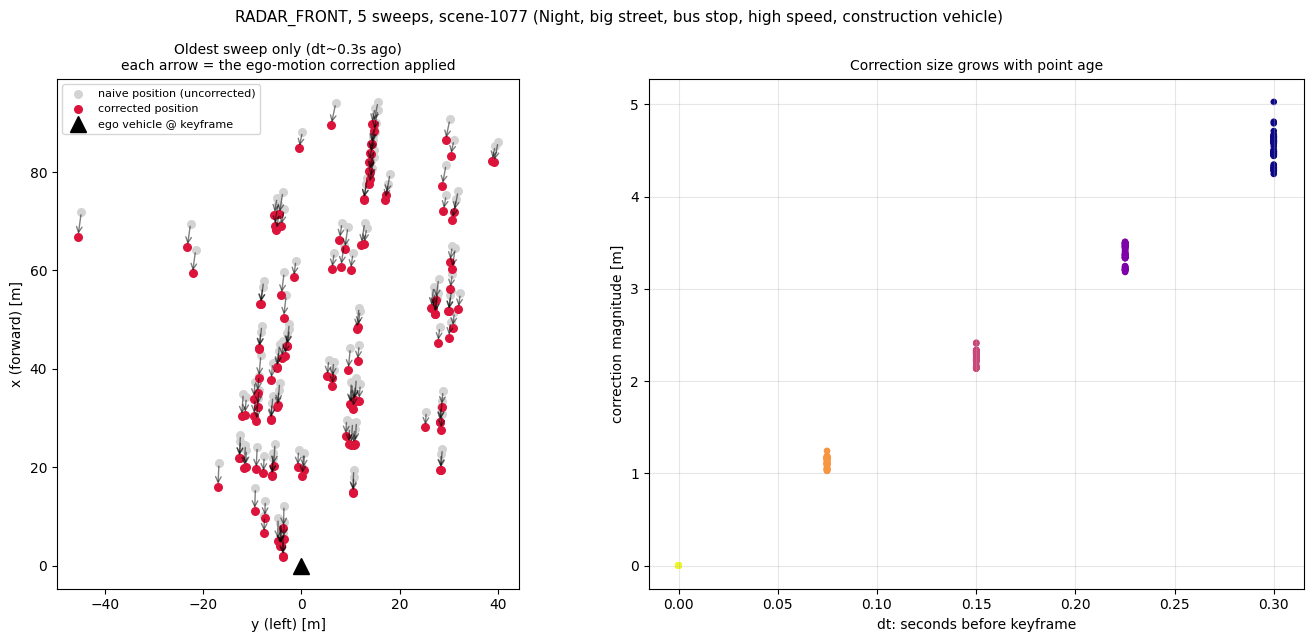

In [6]:
def load_sweeps_naive_vs_aligned(nusc, sample, sensor, n_sweeps=5):
    """Same transform as load_radar_sweeps, but also keeps the pre-ego-correction
    position (sensor -> ego(t_i), then stop) for comparison. Returns (aligned, naive),
    each (N, 3) = [x, y, dt]."""
    key_sd = nusc.get("sample_data", sample["data"][sensor])
    R_ke, t_ke = pose(nusc.get("ego_pose", key_sd["ego_pose_token"]))
    sd, aligned, naive = key_sd, [], []
    for _ in range(n_sweeps):
        p = RadarPointCloud.from_file(str(DATAROOT / sd["filename"])).points
        R_cs, t_cs = pose(nusc.get("calibrated_sensor", sd["calibrated_sensor_token"]))
        R_ge, t_ge = pose(nusc.get("ego_pose", sd["ego_pose_token"]))

        xyz = R_cs @ p[:3] + t_cs[:, None]           # sensor -> ego(t_i)
        naive_xy = xyz[:2].copy()                    # naive: pretend ego(t_i) == ego(keyframe)
        xyz = R_ge @ xyz + t_ge[:, None]              # -> global
        xyz = R_ke.T @ (xyz - t_ke[:, None])          # -> ego(keyframe)  [properly aligned]

        dt = np.full(p.shape[1], (key_sd["timestamp"] - sd["timestamp"]) * 1e-6)
        aligned.append(np.stack([xyz[0], xyz[1], dt], axis=1))
        naive.append(np.stack([naive_xy[0], naive_xy[1], dt], axis=1))
        if not sd["prev"]:
            break
        sd = nusc.get("sample_data", sd["prev"])
    return np.concatenate(aligned).astype(np.float32), np.concatenate(naive).astype(np.float32)


demo_scene = next(s for s in nusc.scene if s["name"] == "scene-1077")
demo_token = demo_scene["first_sample_token"]
for _ in range(40):
    demo_token = nusc.get("sample", demo_token)["next"]
demo_sample = nusc.get("sample", demo_token)

aligned, naive = load_sweeps_naive_vs_aligned(nusc, demo_sample, "RADAR_FRONT", n_sweeps=5)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))

ax = axes[0]
old = aligned[:, 2] > 0.2  # oldest sweep only, so arrows don't overlap
ax.scatter(-naive[old, 1], naive[old, 0], c="lightgray", s=30, label="naive position (uncorrected)")
ax.scatter(-aligned[old, 1], aligned[old, 0], c="crimson", s=30, label="corrected position")
for i in np.where(old)[0]:
    ax.annotate("", xy=(-aligned[i, 1], aligned[i, 0]), xytext=(-naive[i, 1], naive[i, 0]),
                arrowprops=dict(arrowstyle="->", color="black", alpha=0.5, lw=1))
ax.plot(0, 0, "k^", ms=12, label="ego vehicle @ keyframe")
ax.set_xlabel("y (left) [m]"); ax.set_ylabel("x (forward) [m]")
ax.set_title("Oldest sweep only (dt~0.3s ago)\neach arrow = the ego-motion correction applied", fontsize=10)
ax.set_aspect("equal"); ax.legend(loc="upper left", fontsize=8)

ax = axes[1]
shift = np.linalg.norm(aligned[:, :2] - naive[:, :2], axis=1)
ax.scatter(aligned[:, 2], shift, c=aligned[:, 2], cmap="plasma_r", s=14)
ax.set_xlabel("dt: seconds before keyframe"); ax.set_ylabel("correction magnitude [m]")
ax.set_title("Correction size grows with point age", fontsize=10)
ax.grid(alpha=0.3)

fig.suptitle(f"RADAR_FRONT, 5 sweeps, {demo_scene['name']} ({demo_scene['description']})", fontsize=11)
plt.tight_layout()
plt.show()

### 1c. Ego-motion correction is not object-motion correction

`load_radar_sweeps` only undoes the *ego* vehicle's motion between sweeps (1b above). It does nothing about a *moving object's* own motion: an old sweep's return still sits at the object's position from `dt` seconds ago, not where the object is now. The cell below is a **synthetic schematic** (exact numbers, not real data) showing this: 5 returns from a car crossing at 15 m/s, ego-motion-corrected -- they trail off behind the car's true current position -- versus the same points additionally corrected by `pos + v_obj * dt`, which collapses them back onto the true position. This is exactly why `dt` and per-point `vx, vy` are both kept as pillar features: together they carry what a learned encoder needs to undo this smear.

Why not show this with real nuScenes points? I tried it first: took the fastest nearby vehicle in scene-1077 (~22 m/s) and pooled all radar returns within 8m of its annotated box across 5 sweeps. The per-sweep centroids didn't trend smoothly (they jumped between -30m and -34m) -- with only ~5 points/sweep near any one object, that neighborhood mixes clutter and other reflectors rather than isolating one clean track. Real nuScenes radar is too sparse for a clean single-object trace without a proper clustering/association step first -- one more reason a learned pillar encoder (which can weigh points probabilistically) beats naive per-point heuristics here.</cell>


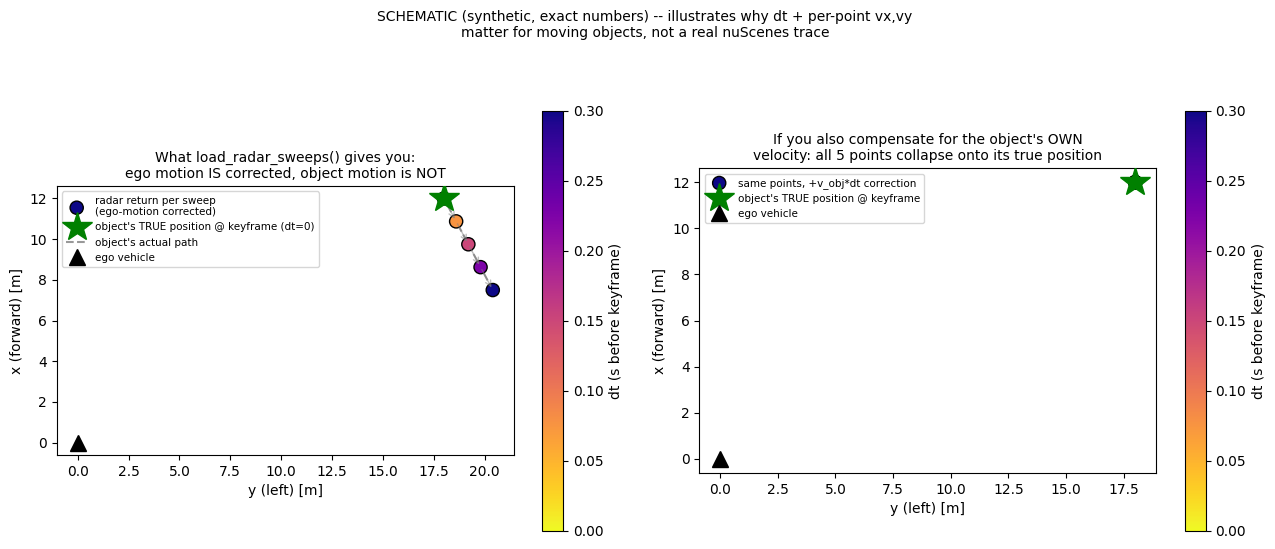

In [7]:
# SCHEMATIC (synthetic, exact numbers) -- not a real nuScenes trace.
# A car crossing in front of the ego vehicle at 15 m/s, radar-detected once per
# sweep. Each point already has perfect ego-motion correction (as in 1b); we
# then check whether that alone is enough to recover the object's true current
# position, and whether adding v_obj * dt on top of it fixes the rest.
dts = np.array([0.30, 0.225, 0.15, 0.075, 0.0])          # oldest -> newest
obj_pos_keyframe = np.array([12.0, 18.0])                 # object's true (x, y) at dt=0
obj_vel = np.array([15.0, -8.0])                          # object's true velocity, m/s (ego frame)

true_pos_at_dt = obj_pos_keyframe[None, :] - obj_vel[None, :] * dts[:, None]  # where it truly was
motion_compensated = true_pos_at_dt + obj_vel[None, :] * dts[:, None]         # + v_obj*dt correction

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

ax = axes[0]
sc = ax.scatter(true_pos_at_dt[:, 1], true_pos_at_dt[:, 0], c=dts, cmap="plasma_r", s=90,
                 edgecolors="k", zorder=3, label="radar return per sweep\n(ego-motion corrected)")
ax.plot(obj_pos_keyframe[1], obj_pos_keyframe[0], "g*", ms=22, zorder=4, label="object's TRUE position @ keyframe (dt=0)")
ax.plot(true_pos_at_dt[:, 1], true_pos_at_dt[:, 0], "k--", alpha=0.4, zorder=1, label="object's actual path")
ax.plot(0, 0, "k^", ms=12, label="ego vehicle")
for i in range(len(dts) - 1):
    ax.annotate("", xy=true_pos_at_dt[i][::-1], xytext=true_pos_at_dt[i + 1][::-1],
                arrowprops=dict(arrowstyle="->", color="gray", alpha=0.5))
ax.set_xlabel("y (left) [m]"); ax.set_ylabel("x (forward) [m]")
ax.set_title("What load_radar_sweeps() gives you:\nego motion IS corrected, object motion is NOT", fontsize=10)
ax.set_aspect("equal"); ax.legend(loc="upper left", fontsize=7.5)
fig.colorbar(sc, ax=ax, label="dt (s before keyframe)", shrink=0.8)

ax = axes[1]
sc = ax.scatter(motion_compensated[:, 1], motion_compensated[:, 0], c=dts, cmap="plasma_r", s=90,
                 edgecolors="k", zorder=3, label="same points, +v_obj*dt correction")
ax.plot(obj_pos_keyframe[1], obj_pos_keyframe[0], "g*", ms=22, zorder=4, label="object's TRUE position @ keyframe")
ax.plot(0, 0, "k^", ms=12, label="ego vehicle")
ax.set_xlabel("y (left) [m]"); ax.set_ylabel("x (forward) [m]")
ax.set_title("If you also compensate for the object's OWN\nvelocity: all 5 points collapse onto its true position", fontsize=10)
ax.set_aspect("equal"); ax.legend(loc="upper left", fontsize=7.5)
fig.colorbar(sc, ax=ax, label="dt (s before keyframe)", shrink=0.8)

fig.suptitle("SCHEMATIC (synthetic, exact numbers) -- illustrates why dt + per-point vx,vy\n"
             "matter for moving objects, not a real nuScenes trace", fontsize=10)
plt.tight_layout()
plt.show()

## 2. Pillarization

Grid: 102.4 m x 102.4 m at 0.8 m per cell = 128 x 128 (row = x forward, column = y left). Channels per cell: point count, mean vx, mean vy, mean radial velocity, mean RCS, max RCS, mean dt. This is a hand-crafted feature map for now; the learned pillar encoder (PointNet-style) comes next and will take the raw per-point features instead.

In [8]:
GRID = dict(x0=-51.2, y0=-51.2, cell=0.8, nx=128, ny=128)
CHANNELS = ["count", "mean_vx", "mean_vy", "mean_v_r", "mean_rcs", "max_rcs", "mean_dt"]


def pillarize(pts, g=GRID):
    """(N, 8) ego-frame points -> (len(CHANNELS), nx, ny) BEV map. Dim 1 = x (forward), dim 2 = y (left)."""
    ix = np.floor((pts[:, 0] - g["x0"]) / g["cell"]).astype(int)
    iy = np.floor((pts[:, 1] - g["y0"]) / g["cell"]).astype(int)
    keep = (ix >= 0) & (ix < g["nx"]) & (iy >= 0) & (iy < g["ny"])
    pts, ix, iy = pts[keep], ix[keep], iy[keep]
    flat = ix * g["ny"] + iy
    size = g["nx"] * g["ny"]

    count = np.bincount(flat, minlength=size).astype(np.float32)
    denom = np.maximum(count, 1.0)
    mean = lambda col: np.bincount(flat, weights=pts[:, col], minlength=size) / denom
    max_rcs = np.full(size, -np.inf, dtype=np.float32)
    np.maximum.at(max_rcs, flat, pts[:, 6])
    max_rcs[~np.isfinite(max_rcs)] = 0.0

    bev = np.stack([count, mean(3), mean(4), mean(5), mean(6), max_rcs, mean(7)])
    return bev.reshape(len(CHANNELS), g["nx"], g["ny"]).astype(np.float32)


pts = load_keyframe_radar(nusc, sample, n_sweeps=5)
bev = pillarize(pts)
occ = (bev[0] > 0).mean()
print("BEV", bev.shape, bev.dtype, f"| occupied cells {occ:.2%} | points kept {int(bev[0].sum())}/{len(pts)}")

BEV (7, 128, 128) float32 | occupied cells 2.70% | points kept 766/1187


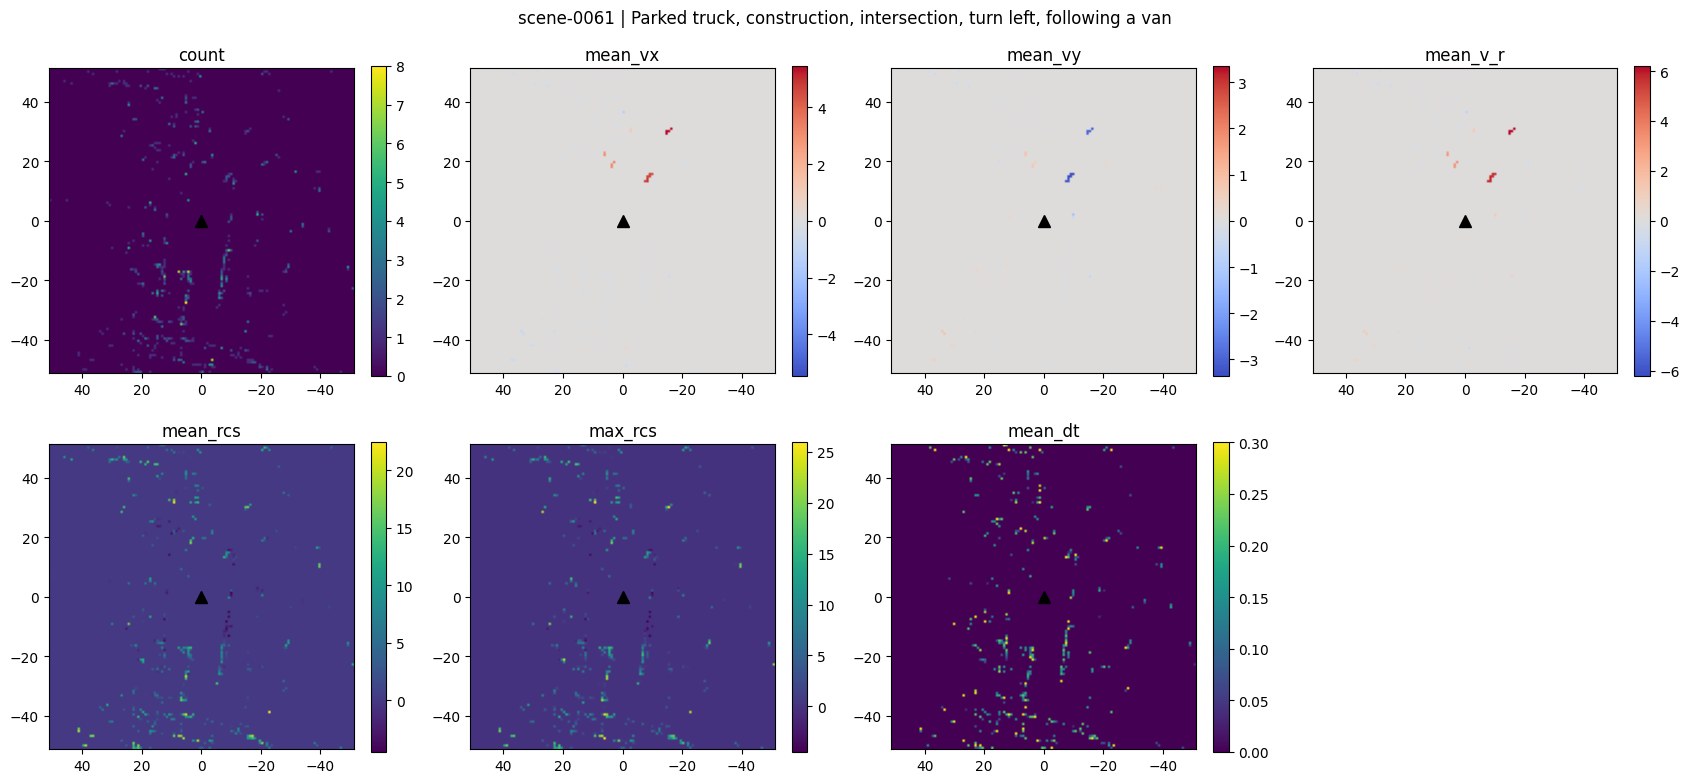

In [9]:
def show_bev(bev, title=""):
    fig, axes = plt.subplots(2, 4, figsize=(17, 8))
    ext = [GRID["y0"] + GRID["ny"] * GRID["cell"], GRID["y0"], GRID["x0"], GRID["x0"] + GRID["nx"] * GRID["cell"]]
    for ax, name, ch in zip(axes.flat, CHANNELS, bev):
        img = ch[::-1, ::-1]                  # up = forward, left = left
        vmax = max(np.abs(img).max(), 1e-6)
        sym = name in ("mean_vx", "mean_vy", "mean_v_r")
        im = ax.imshow(img, cmap="coolwarm" if sym else "viridis", extent=ext, vmin=-vmax if sym else None, vmax=vmax)
        ax.plot(0, 0, "k^", ms=8)
        ax.set_title(name)
        fig.colorbar(im, ax=ax, fraction=0.046)
    axes.flat[-1].axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show_bev(bev, f"{scene['name']} | {scene['description']}")

### 2b. The pillarization figures, explained in plain words

**First figure -- dots to pixels.** Zoom into the busiest 16 m x 16 m patch. Left: the raw radar dots with a 0.8 m grid laid over the ground. Right: every grid square becomes one pixel, and the number is how many dots fell inside it. That is the `count` layer. All other layers are built the same way (average or max of the dots in the square).

**Second figure -- the 7 layers, each labelled with what it means.** Circles mark an example pixel (the extreme value of that layer). Two things to remember: most of the map is empty (about 97%), and an empty pixel is filled with 0, which looks the same as a real value of 0 -- only `count` says whether a pixel has data.

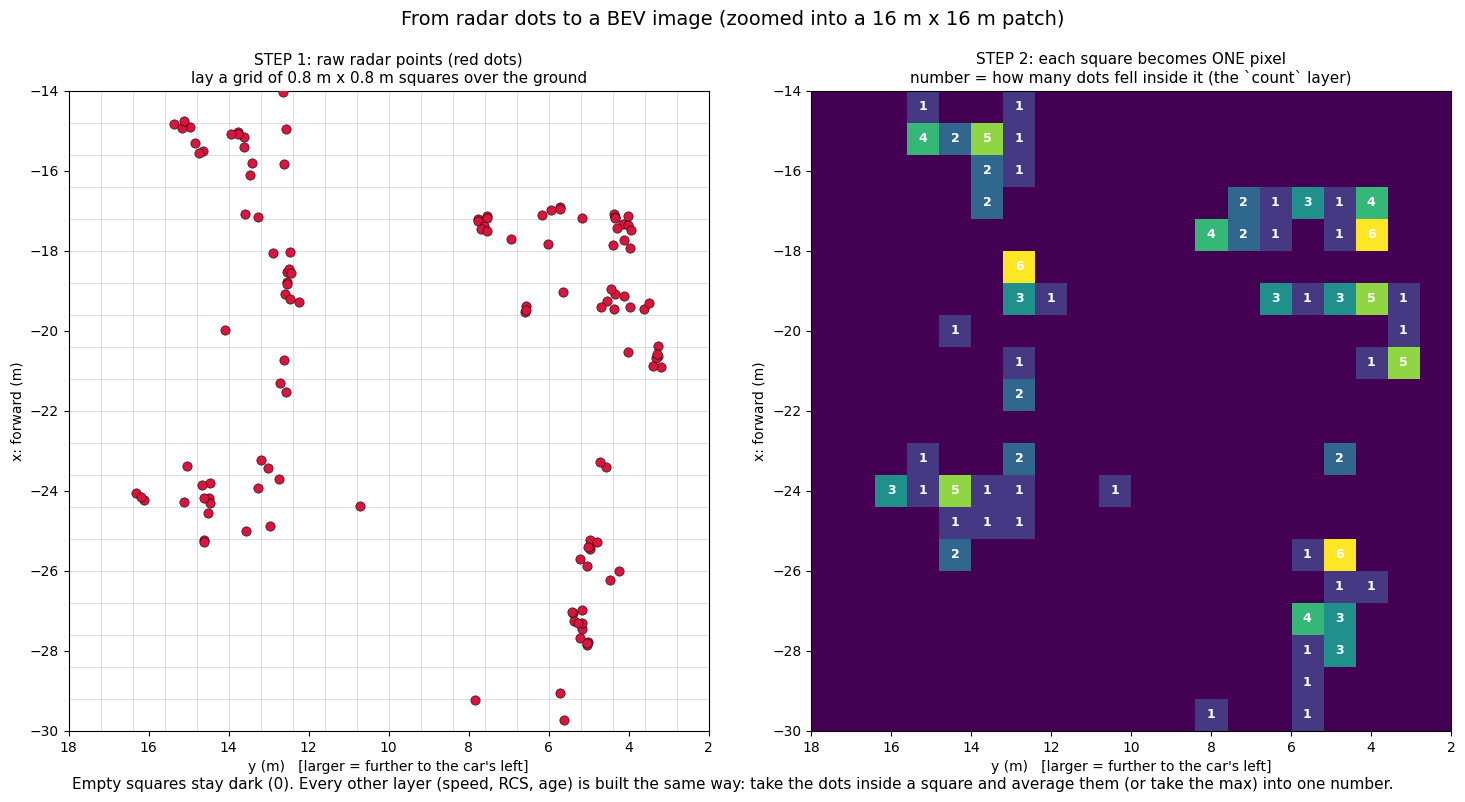

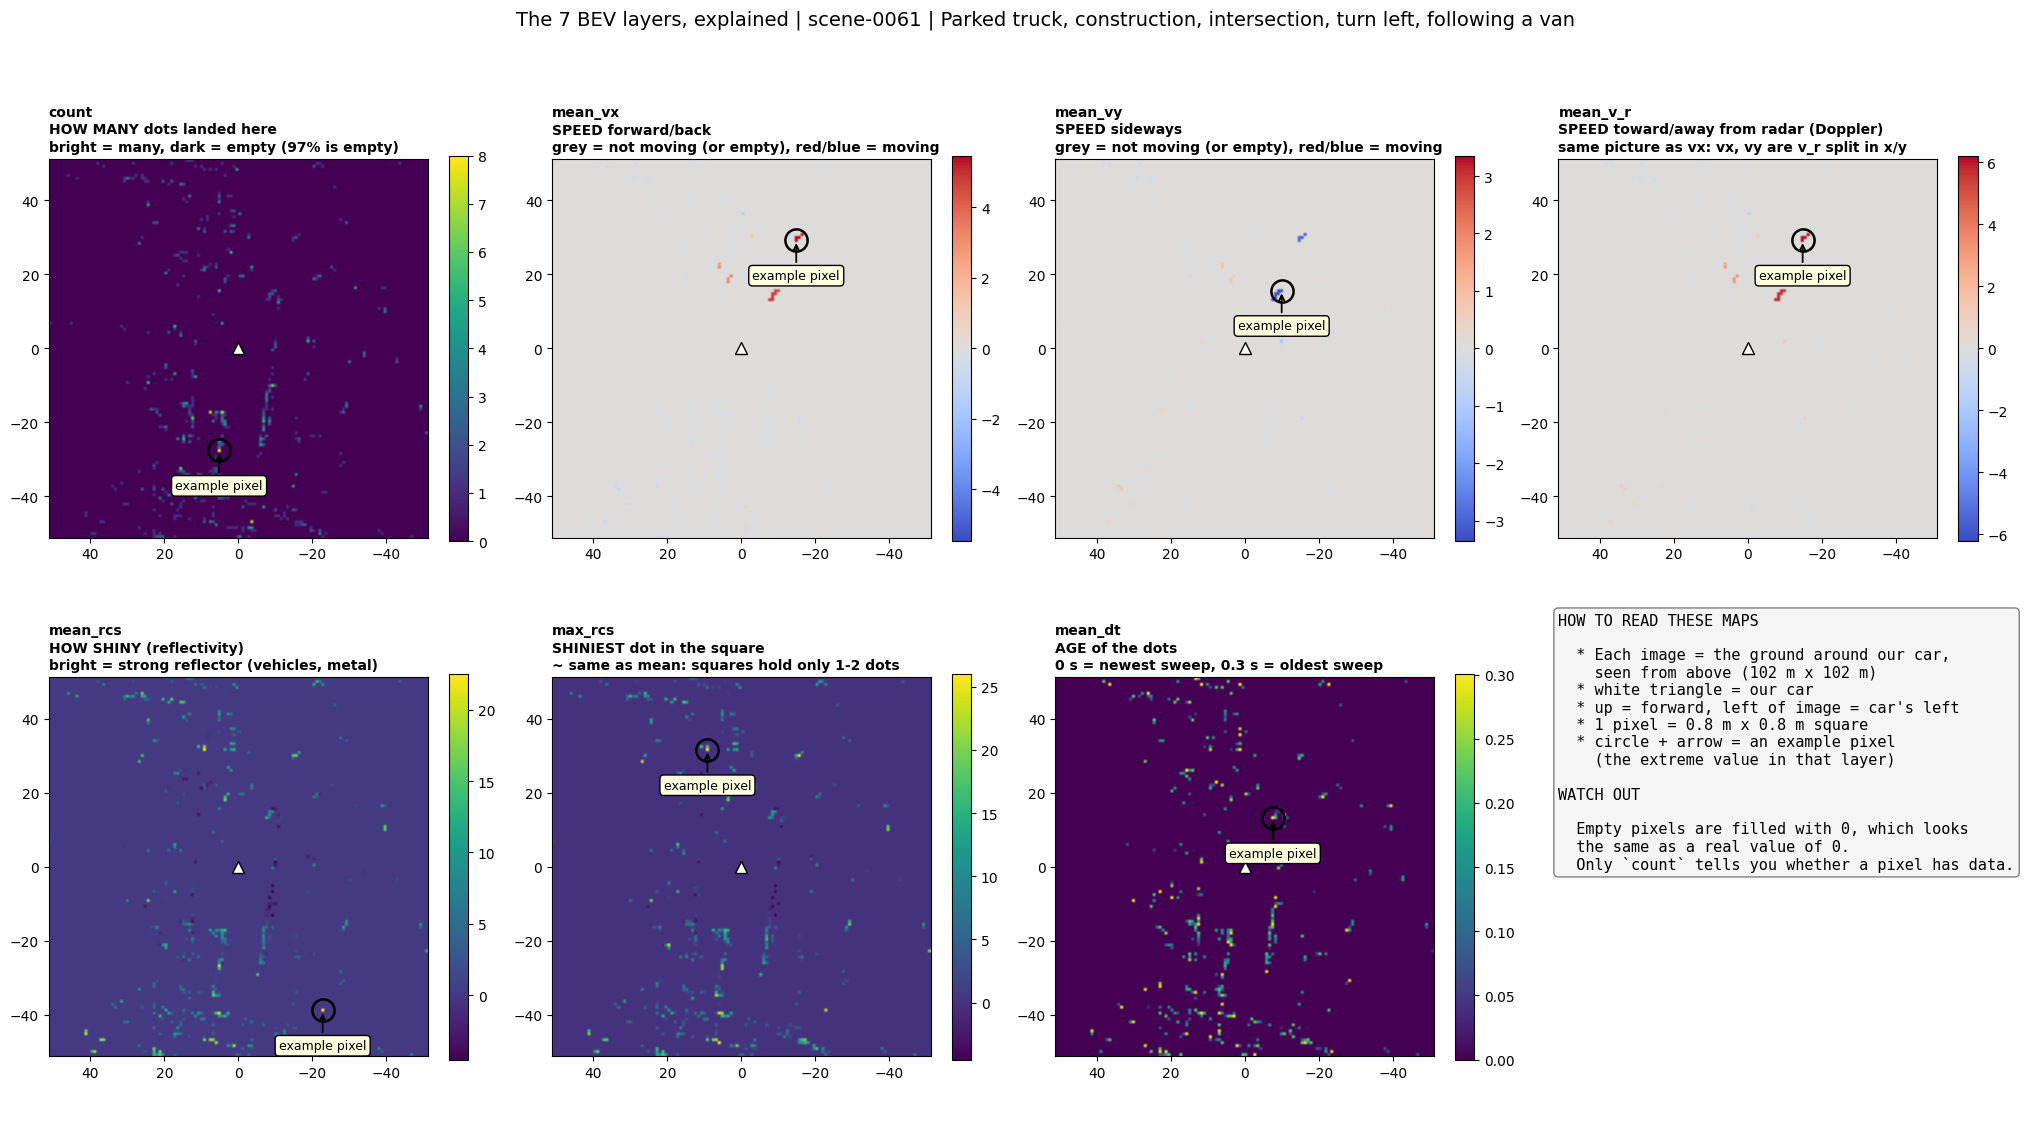

In [10]:
def cell_center(ix, iy, g=GRID):
    """Grid index -> (x forward, y left) in metres, cell centre."""
    return g["x0"] + (ix + 0.5) * g["cell"], g["y0"] + (iy + 0.5) * g["cell"]


# ---------- Figure A: how points become pixels (zoom into the busiest 16 m x 16 m window) ----------
win = 16.0
xs = np.arange(-50, 50 - win, 2.0)
best = max(((xa, ya) for xa in xs for ya in xs),
           key=lambda w: ((pts[:, 0] >= w[0]) & (pts[:, 0] < w[0] + win) & (pts[:, 1] >= w[1]) & (pts[:, 1] < w[1] + win)).sum())
xa, ya = best
inwin = (pts[:, 0] >= xa) & (pts[:, 0] < xa + win) & (pts[:, 1] >= ya) & (pts[:, 1] < ya + win)
edges_x = np.arange(xa, xa + win + 1e-6, GRID["cell"])
edges_y = np.arange(ya, ya + win + 1e-6, GRID["cell"])
H, _, _ = np.histogram2d(pts[inwin, 0], pts[inwin, 1], bins=[edges_x, edges_y])

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
ax = axes[0]
for e in edges_x:
    ax.axhline(e, color="0.85", lw=0.6)
for e in edges_y:
    ax.axvline(e, color="0.85", lw=0.6)
ax.scatter(pts[inwin, 1], pts[inwin, 0], s=45, c="crimson", edgecolors="k", linewidths=0.4, zorder=3)
ax.set_xlim(ya + win, ya)
ax.set_ylim(xa, xa + win)
ax.set_aspect("equal")
ax.set_xlabel("y (m)   [larger = further to the car's left]")
ax.set_ylabel("x: forward (m)")
ax.set_title("STEP 1: raw radar points (red dots)\nlay a grid of 0.8 m x 0.8 m squares over the ground", fontsize=11)

ax = axes[1]
ax.imshow(H[::-1, ::-1], extent=[ya + win, ya, xa, xa + win], cmap="viridis", vmin=0, vmax=max(H.max(), 3))
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        if H[i, j] > 0:
            cx, cy = xa + (i + 0.5) * GRID["cell"], ya + (j + 0.5) * GRID["cell"]
            ax.text(cy, cx, int(H[i, j]), color="w", ha="center", va="center", fontsize=9, fontweight="bold")
ax.set_xlim(ya + win, ya)
ax.set_ylim(xa, xa + win)
ax.set_aspect("equal")
ax.set_xlabel("y (m)   [larger = further to the car's left]")
ax.set_ylabel("x: forward (m)")
ax.set_title("STEP 2: each square becomes ONE pixel\nnumber = how many dots fell inside it (the `count` layer)", fontsize=11)
fig.text(0.5, 0.012, "Empty squares stay dark (0). Every other layer (speed, RCS, age) is built the same way: "
         "take the dots inside a square and average them (or take the max) into one number.",
         ha="center", va="bottom", fontsize=11)
fig.suptitle("From radar dots to a BEV image (zoomed into a 16 m x 16 m patch)", fontsize=14, y=0.99)
plt.tight_layout(rect=[0, 0.07, 1, 0.95])
plt.show()

# ---------- Figure B: the 7 layers with plain-language labels ----------
def hot(ch, absval=False):
    a = np.abs(bev[ch]) if absval else bev[ch]
    ix, iy = np.unravel_index(np.argmax(a), a.shape)
    x, y = cell_center(ix, iy)
    return y, x                                            # plot coords: horizontal = y, vertical = x


notes = {
    "count": ("HOW MANY dots landed here\nbright = many, dark = empty (97% is empty)", False),
    "mean_vx": ("SPEED forward/back\ngrey = not moving (or empty), red/blue = moving", True),
    "mean_vy": ("SPEED sideways\ngrey = not moving (or empty), red/blue = moving", True),
    "mean_v_r": ("SPEED toward/away from radar (Doppler)\nsame picture as vx: vx, vy are v_r split in x/y", True),
    "mean_rcs": ("HOW SHINY (reflectivity)\nbright = strong reflector (vehicles, metal)", False),
    "max_rcs": ("SHINIEST dot in the square\n~ same as mean: squares hold only 1-2 dots", False),
    "mean_dt": ("AGE of the dots\n0 s = newest sweep, 0.3 s = oldest sweep", False),
}

fig, axes = plt.subplots(2, 4, figsize=(21, 11.5))
ext = [GRID["y0"] + GRID["ny"] * GRID["cell"], GRID["y0"], GRID["x0"], GRID["x0"] + GRID["nx"] * GRID["cell"]]
for k, (ax, name, ch) in enumerate(zip(axes.flat, CHANNELS, bev)):
    img = ch[::-1, ::-1]
    vmax = max(np.abs(img).max(), 1e-6)
    sym = name in ("mean_vx", "mean_vy", "mean_v_r")
    im = ax.imshow(img, cmap="coolwarm" if sym else "viridis", extent=ext, vmin=-vmax if sym else None, vmax=vmax)
    ax.plot(0, 0, "w^", ms=9, mec="k")
    text, absval = notes[name]
    ax.set_title(name + "\n" + text, fontsize=10, fontweight="bold", loc="left", linespacing=1.3)
    fig.colorbar(im, ax=ax, fraction=0.046)
    target = hot(k, absval=absval)
    ax.plot(*target, "o", mfc="none", mec="k", ms=16, mew=1.8)
    ax.annotate("example pixel", xy=target, xytext=(0, -28), textcoords="offset points", ha="center", fontsize=9,
                bbox=dict(boxstyle="round", fc="lightyellow", ec="k"), arrowprops=dict(arrowstyle="->", color="k", lw=1.3))

ax = axes.flat[-1]
ax.axis("off")
ax.text(0.0, 1.0,
        "HOW TO READ THESE MAPS\n\n"
        "  * Each image = the ground around our car,\n    seen from above (102 m x 102 m)\n"
        "  * white triangle = our car\n"
        "  * up = forward, left of image = car's left\n"
        "  * 1 pixel = 0.8 m x 0.8 m square\n"
        "  * circle + arrow = an example pixel\n    (the extreme value in that layer)\n\n"
        "WATCH OUT\n\n"
        "  Empty pixels are filled with 0, which looks\n  the same as a real value of 0.\n"
        "  Only `count` tells you whether a pixel has data.",
        va="top", ha="left", fontsize=11, family="monospace",
        bbox=dict(boxstyle="round", fc="whitesmoke", ec="0.5"))
fig.suptitle(f"The 7 BEV layers, explained | {scene['name']} | {scene['description']}", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 3. Dataset over all keyframes (with cache)

The functions from sections 1-2 now live in `code/radar/pillar_dataset.py` so training code can import them. `RadarPillarDataset` gives one item per keyframe:

- `points` -- the raw multi-sweep points `(N, 8)`; this is what the learned PointNet pillar encoder will consume
- `bev` -- the hand-crafted `(7, 128, 128)` map from section 2, recomputed on the fly (it is cheap)

Raw points are cached per keyframe in `cache/radar_points/`: the first pass reads ~25 radar files per keyframe (about 2 minutes for mini), later passes read one `.npy` (about 3 seconds). The split is by **scene** (nuScenes `mini_train` / `mini_val`), so train and val never share a scene. `N` differs per keyframe, so `collate` pads to the largest `N` in the batch and returns a boolean `mask`.

`drop_first=True` skips that first keyframe (used for the train split below; val keeps every keyframe). Section 3b shows the quirk behind it: the first keyframe of every scene has ~5x fewer points, because there are no earlier sweeps to accumulate.

In [11]:
import importlib

from torch.utils.data import DataLoader

sys.path.insert(0, str(ROOT / "code" / "radar"))
import pillar_dataset
importlib.reload(pillar_dataset)
from pillar_dataset import RadarPillarDataset, collate

train_ds = RadarPillarDataset(nusc, "mini_train", drop_first=True)   # keyframe 0 of each scene has ~5x fewer points: not used for training
val_ds = RadarPillarDataset(nusc, "mini_val")
for name, ds in (("train", train_ds), ("val", val_ds)):
    secs = ds.prepare()   # first run fills cache/radar_points/, later runs just read it
    print(f"{name}: {len(ds)} keyframes, {len({nusc.get('sample', t)['scene_token'] for t in ds.tokens})} scenes | prepare {secs:.1f}s")

# 1) the dataset reproduces the numbers from section 2 (scene-0061, keyframe 10)
same_pts = np.array_equal(pillar_dataset.load_keyframe_radar(nusc, sample), pts)
same_bev = np.array_equal(pillar_dataset.pillarize(pts), bev)
print("matches section 2 -> points:", same_pts, "| bev:", same_bev)

# 2) one batch
batch = next(iter(DataLoader(train_ds, batch_size=8, shuffle=True, collate_fn=collate)))
print({k: (tuple(v.shape) if hasattr(v, "shape") else f"{len(v)} tokens") for k, v in batch.items()})
print("real points per item:", batch["mask"].sum(1).tolist())

train: 315 keyframes, 8 scenes | prepare 0.5s
val: 81 keyframes, 2 scenes | prepare 0.0s
matches section 2 -> points: True | bev: True


{'token': '8 tokens', 'points': (8, 1158, 8), 'mask': (8, 1158), 'bev': (8, 7, 128, 128)}
real points per item: [925, 1111, 1005, 1127, 955, 682, 1158, 905]


### 3b. Points per keyframe, explained on the figure

**Top:** why the first keyframe of a scene has fewer points. Each keyframe merges the last 5 radar sweeps (one sweep about every 0.075 s). At keyframe 0 only one sweep exists, so 1 sweep x 5 radars gives about 185 points; from keyframe 1 on, 5 sweeps x 5 radars gives about 1000.

**Bottom:** the number of points in every keyframe of every scene (blue = train, red = val). The yellow band is keyframe 0 and the green arrow is the jump once all 5 sweeps are available. After that the counts stay roughly flat, but scenes differ from each other by about 2x, another reason to split train/val by scene.

Decision: keyframe 0 is dropped from the training split (`drop_first=True`); the val split keeps it.

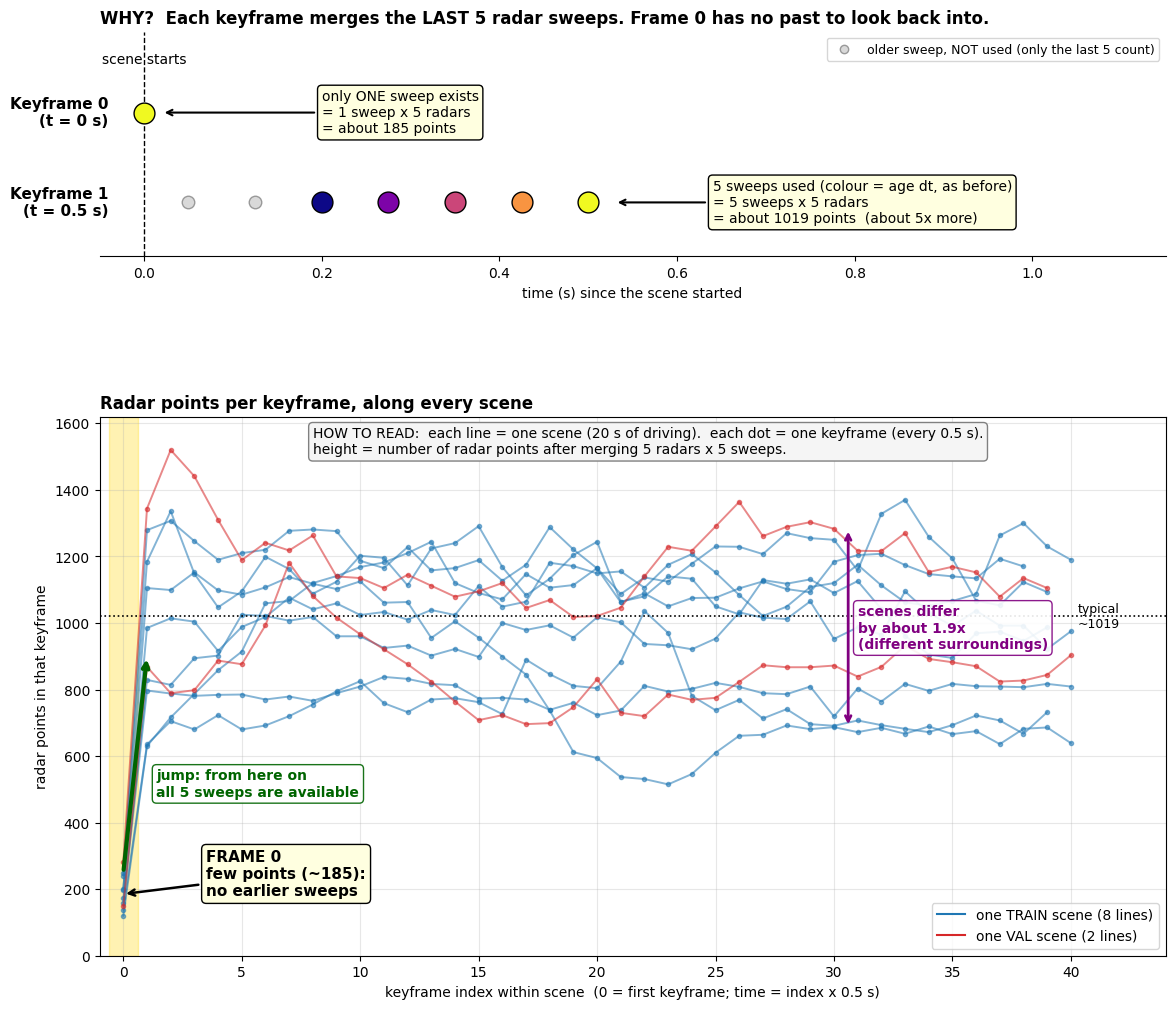

In [12]:
counts = {}                                        # (split, scene token) -> points per keyframe, in time order
all_train, all_val = RadarPillarDataset(nusc, "mini_train"), RadarPillarDataset(nusc, "mini_val")   # incl. frame 0
for ds, split in ((all_train, "train"), (all_val, "val")):
    for t in ds.tokens:
        s = nusc.get("sample", t)
        counts.setdefault((split, s["scene_token"]), []).append(len(ds.points(t)))
typical = np.median(np.concatenate([c[1:] for c in counts.values()]))
frame0 = np.median([c[0] for c in counts.values()])

fig = plt.figure(figsize=(13, 10.5))
gs = fig.add_gridspec(2, 1, height_ratios=[1, 2.4], hspace=0.42, left=0.15, right=0.97, top=0.95, bottom=0.07)

# ---------- top: WHY frame 0 has fewer points (sweep timeline) ----------
ax = fig.add_subplot(gs[0])
step = 0.075                                       # radar sweeps arrive every ~0.075 s
ax.set_title("WHY?  Each keyframe merges the LAST 5 radar sweeps. Frame 0 has no past to look back into.",
             fontsize=12, fontweight="bold", loc="left")
rows = ((0, "Keyframe 1\n(t = 0.5 s)", 0.5), (1, "Keyframe 0\n(t = 0 s)", 0.0))
for row, label, t_key in rows:
    for k in range(9):
        t = t_key - k * step
        if t < -1e-9:
            continue                               # the scene starts at t = 0: no sweeps before it
        used = k < 5
        ax.plot(t, row, "o", ms=15 if used else 9, mfc=plt.cm.plasma_r(min(k * step / 0.3, 1)) if used else "0.85",
                mec="k" if used else "0.6", zorder=3)
    ax.text(-0.04, row, label, ha="right", va="center", fontsize=11, fontweight="bold")
ax.axvline(0, color="k", ls="--", lw=1)
ax.text(0.0, 1.55, "scene starts", ha="center", fontsize=10)
ax.annotate("only ONE sweep exists\n= 1 sweep x 5 radars\n= about %d points" % frame0, xy=(0.02, 1), xytext=(0.2, 1),
            fontsize=10, va="center", bbox=dict(boxstyle="round", fc="lightyellow", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.annotate("5 sweeps used (colour = age dt, as before)\n= 5 sweeps x 5 radars\n= about %d points  (about 5x more)" % typical,
            xy=(0.53, 0), xytext=(0.64, 0), fontsize=10, va="center",
            bbox=dict(boxstyle="round", fc="lightyellow", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.plot([], [], "o", mfc="0.85", mec="0.6", label="older sweep, NOT used (only the last 5 count)")
ax.legend(loc="upper right", fontsize=9)
ax.set_xlim(-0.05, 1.15)
ax.set_ylim(-0.6, 1.9)
ax.set_xlabel("time (s) since the scene started")
ax.set_yticks([])
for side in ("left", "right", "top"):
    ax.spines[side].set_visible(False)

# ---------- bottom: the graph, with callouts ----------
ax = fig.add_subplot(gs[1])
for (split, _), c in counts.items():
    ax.plot(c, color="tab:blue" if split == "train" else "tab:red", alpha=0.55, marker=".", lw=1.4)
ax.plot([], [], color="tab:blue", label="one TRAIN scene (8 lines)")
ax.plot([], [], color="tab:red", label="one VAL scene (2 lines)")
ax.axhline(typical, color="k", ls=":", lw=1.2)
ax.text(40.3, typical, "typical\n~%d" % typical, va="center", fontsize=9)

ax.axvspan(-0.6, 0.6, color="gold", alpha=0.3)
ax.annotate("FRAME 0\nfew points (~%d):\nno earlier sweeps" % frame0, xy=(0, frame0), xytext=(3.5, 180),
            fontsize=11, fontweight="bold", bbox=dict(boxstyle="round", fc="lightyellow", ec="k"),
            arrowprops=dict(arrowstyle="->", lw=1.8))
ax.annotate("", xy=(1, 900), xytext=(0, 250), arrowprops=dict(arrowstyle="->", lw=3, color="darkgreen"))
ax.text(1.4, 480, "jump: from here on\nall 5 sweeps are available", fontsize=10, color="darkgreen", fontweight="bold",
        bbox=dict(boxstyle="round", fc="white", ec="darkgreen", alpha=0.9))

x_spread = 30
vals = [c[x_spread] for c in counts.values() if len(c) > x_spread]
ax.annotate("", xy=(x_spread + 0.6, max(vals)), xytext=(x_spread + 0.6, min(vals)),
            arrowprops=dict(arrowstyle="<->", lw=2, color="purple"))
ax.text(x_spread + 1.0, (max(vals) + min(vals)) / 2,
        "scenes differ\nby about %.1fx\n(different surroundings)" % (max(vals) / min(vals)),
        fontsize=10, color="purple", fontweight="bold", va="center",
        bbox=dict(boxstyle="round", fc="white", ec="purple", alpha=0.9))

ax.text(8, 1590, "HOW TO READ:  each line = one scene (20 s of driving).  each dot = one keyframe (every 0.5 s).\n"
        "height = number of radar points after merging 5 radars x 5 sweeps.", fontsize=10,
        bbox=dict(boxstyle="round", fc="whitesmoke", ec="0.5"), va="top")
ax.set_xlim(-1, 44)
ax.set_ylim(0, 1620)
ax.set_xlabel("keyframe index within scene  (0 = first keyframe; time = index x 0.5 s)")
ax.set_ylabel("radar points in that keyframe")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
ax.set_title("Radar points per keyframe, along every scene", fontsize=12, fontweight="bold", loc="left")
plt.show()

## 4. Ground-truth BEV targets (detection proxy)

Before the LLM, the radar encoder needs a simple task to learn on: **find the cars and pedestrians in the radar map**. The truth comes from nuScenes `sample_annotation` (`vehicle.car` -> car; adult / child / construction worker / police officer -> pedestrian) and is drawn on the same 128 x 128 grid as the radar map (`code/radar/bev_targets.py`). We use the CenterNet recipe:

- `heatmap (2, 128, 128)`: one layer per class, value 1.0 in the square holding the object's centre, fading like a small Gaussian around it. The network's job is to reproduce this.
- `reg (6, 128, 128)` + `reg_mask`: at each centre square only, where inside the square the centre is, log width, log length, and heading as (sin, cos).
- `boxes (M, 6)`: the raw boxes `[class, x, y, w, l, yaw]` in the ego frame, kept for evaluation.

Check done outside the notebook: decoding a box from its heatmap peak + `reg` gives back exactly the original box. The last panel shows how hard the task is for radar alone: only about half of the pedestrians have even one radar dot inside their box.

{'points': (1187, 8), 'bev': (7, 128, 128), 'boxes': (46, 6), 'heatmap': (2, 128, 128), 'reg': (6, 128, 128), 'reg_mask': (128, 128)}


car       :  3815 objects in 315 train keyframes | 73% have >= 1 radar point inside their box
pedestrian:  3236 objects in 315 train keyframes | 50% have >= 1 radar point inside their box


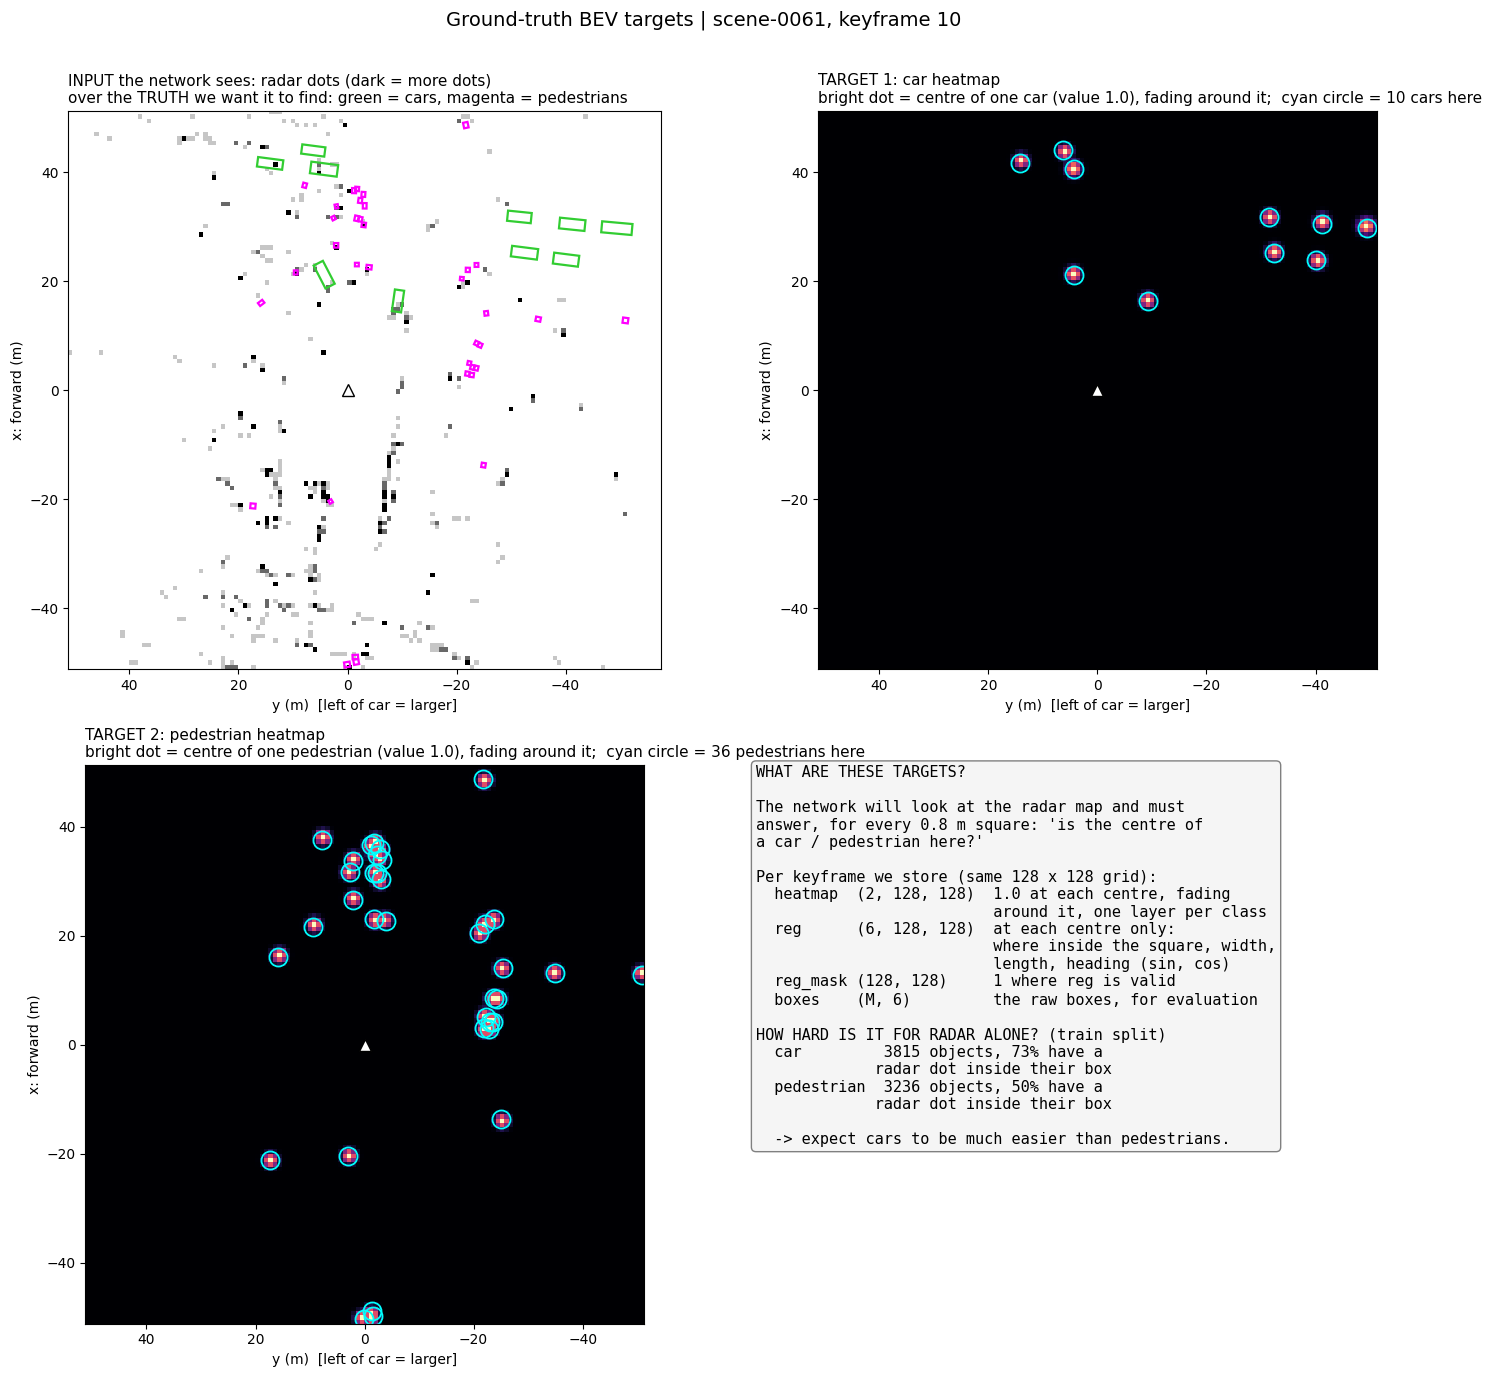

In [13]:
from matplotlib.patches import Polygon

from bev_targets import CLASSES, get_boxes, make_targets

target_ds = RadarPillarDataset(nusc, "mini_train", drop_first=True, with_targets=True)
item = target_ds[target_ds.tokens.index(sample["token"])]           # scene-0061, keyframe 10 (same frame as section 2)
print({k: tuple(v.shape) for k, v in item.items() if hasattr(v, "shape")})

# ---- statistics over the whole train split: how many objects, and how many are visible to radar at all ----
n_obj = np.zeros(2, int)
n_seen = np.zeros(2, int)
for tok in target_ds.tokens:
    p = target_ds.points(tok)
    for cls, x, y, w, l, yaw in get_boxes(nusc, tok, GRID):
        u = np.cos(yaw) * (p[:, 0] - x) + np.sin(yaw) * (p[:, 1] - y)        # point position in the box's own frame
        v = -np.sin(yaw) * (p[:, 0] - x) + np.cos(yaw) * (p[:, 1] - y)
        n_obj[int(cls)] += 1
        n_seen[int(cls)] += bool(((np.abs(u) <= l / 2 + 1) & (np.abs(v) <= w / 2 + 1)).any())   # 1 m margin
for k, name in enumerate(CLASSES):
    print(f"{name:10s}: {n_obj[k]:5d} objects in {len(target_ds)} train keyframes | {n_seen[k] / n_obj[k]:.0%} have >= 1 radar point inside their box")

# ---- one keyframe: the input (radar count) and the two targets ----
boxes = item["boxes"].numpy()
heat = item["heatmap"].numpy()
COLORS = ["limegreen", "magenta"]
ext = [GRID["y0"] + GRID["ny"] * GRID["cell"], GRID["y0"], GRID["x0"], GRID["x0"] + GRID["nx"] * GRID["cell"]]


def draw_boxes(ax, lw=1.6):
    for cls, x, y, w, l, yaw in boxes:
        c, s = np.cos(yaw), np.sin(yaw)
        corners = np.array([[l / 2, w / 2], [l / 2, -w / 2], [-l / 2, -w / 2], [-l / 2, w / 2]])
        xy = corners @ np.array([[c, s], [-s, c]]) + [x, y]                      # rotate by yaw, move to (x, y)
        ax.add_patch(Polygon(np.stack([xy[:, 1], xy[:, 0]], 1), closed=True, fill=False, ec=COLORS[int(cls)], lw=lw))


def base(ax):
    ax.set_xlabel("y (m)  [left of car = larger]")
    ax.set_ylabel("x: forward (m)")
    ax.plot(0, 0, "w^", ms=9, mec="k")


fig, axes = plt.subplots(2, 2, figsize=(15, 14))
ax = axes[0, 0]
ax.imshow(np.minimum(item["bev"][0].numpy(), 3)[::-1, ::-1], extent=ext, cmap="Greys", vmin=0, vmax=3)
draw_boxes(ax)
base(ax)
ax.set_title("INPUT the network sees: radar dots (dark = more dots)\nover the TRUTH we want it to find: green = cars, magenta = pedestrians",
             fontsize=11, loc="left")

for ax, k, name, note in ((axes[0, 1], 0, "car", "TARGET 1: car heatmap"), (axes[1, 0], 1, "pedestrian", "TARGET 2: pedestrian heatmap")):
    ax.imshow(heat[k][::-1, ::-1], extent=ext, cmap="magma", vmin=0, vmax=1)
    for cls, x, y, w, l, yaw in boxes:
        if int(cls) == k:
            ax.plot(y, x, "o", mfc="none", mec="cyan", ms=13, mew=1.3)
    base(ax)
    ax.set_title(f"{note}\nbright dot = centre of one {name} (value 1.0), fading around it;  cyan circle = {int((boxes[:, 0] == k).sum())} {name}s here",
                 fontsize=11, loc="left")

ax = axes[1, 1]
ax.axis("off")
ax.text(0.0, 1.0,
        "WHAT ARE THESE TARGETS?\n\n"
        "The network will look at the radar map and must\nanswer, for every 0.8 m square: 'is the centre of\na car / pedestrian here?'\n\n"
        "Per keyframe we store (same 128 x 128 grid):\n"
        "  heatmap  (2, 128, 128)  1.0 at each centre, fading\n"
        "                          around it, one layer per class\n"
        "  reg      (6, 128, 128)  at each centre only:\n"
        "                          where inside the square, width,\n"
        "                          length, heading (sin, cos)\n"
        "  reg_mask (128, 128)     1 where reg is valid\n"
        "  boxes    (M, 6)         the raw boxes, for evaluation\n\n"
        "HOW HARD IS IT FOR RADAR ALONE? (train split)\n"
        + "\n".join(f"  {name:10s} {n_obj[k]:5d} objects, {n_seen[k] / n_obj[k]:.0%} have a\n"
                    f"  {'':10s} radar dot inside their box" for k, name in enumerate(CLASSES)) +
        "\n\n  -> expect cars to be much easier than pedestrians.",
        va="top", ha="left", fontsize=11, family="monospace", bbox=dict(boxstyle="round", fc="whitesmoke", ec="0.5"))
fig.suptitle(f"Ground-truth BEV targets | {scene['name']}, keyframe 10", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### 4b. The same moment in the cameras

The radar map above is hard to judge by eye, so here is the same keyframe (scene-0061, keyframe 10) through all 6 cameras. The ground-truth boxes from section 4 are drawn on the pictures: green = cars, magenta = pedestrians. The second figure puts the camera view cones on the radar map so you can match each picture to its part of the map.

What to notice: this is a construction site with a crowd of pedestrians (the annotations list 35 adults and 4 construction workers in this keyframe) standing behind the barriers. The camera shows clearly what the radar only hints at with a few dots. Trucks, buses, barriers and cones are also annotated in nuScenes, but the detection proxy only uses cars and pedestrians, so they are not drawn.

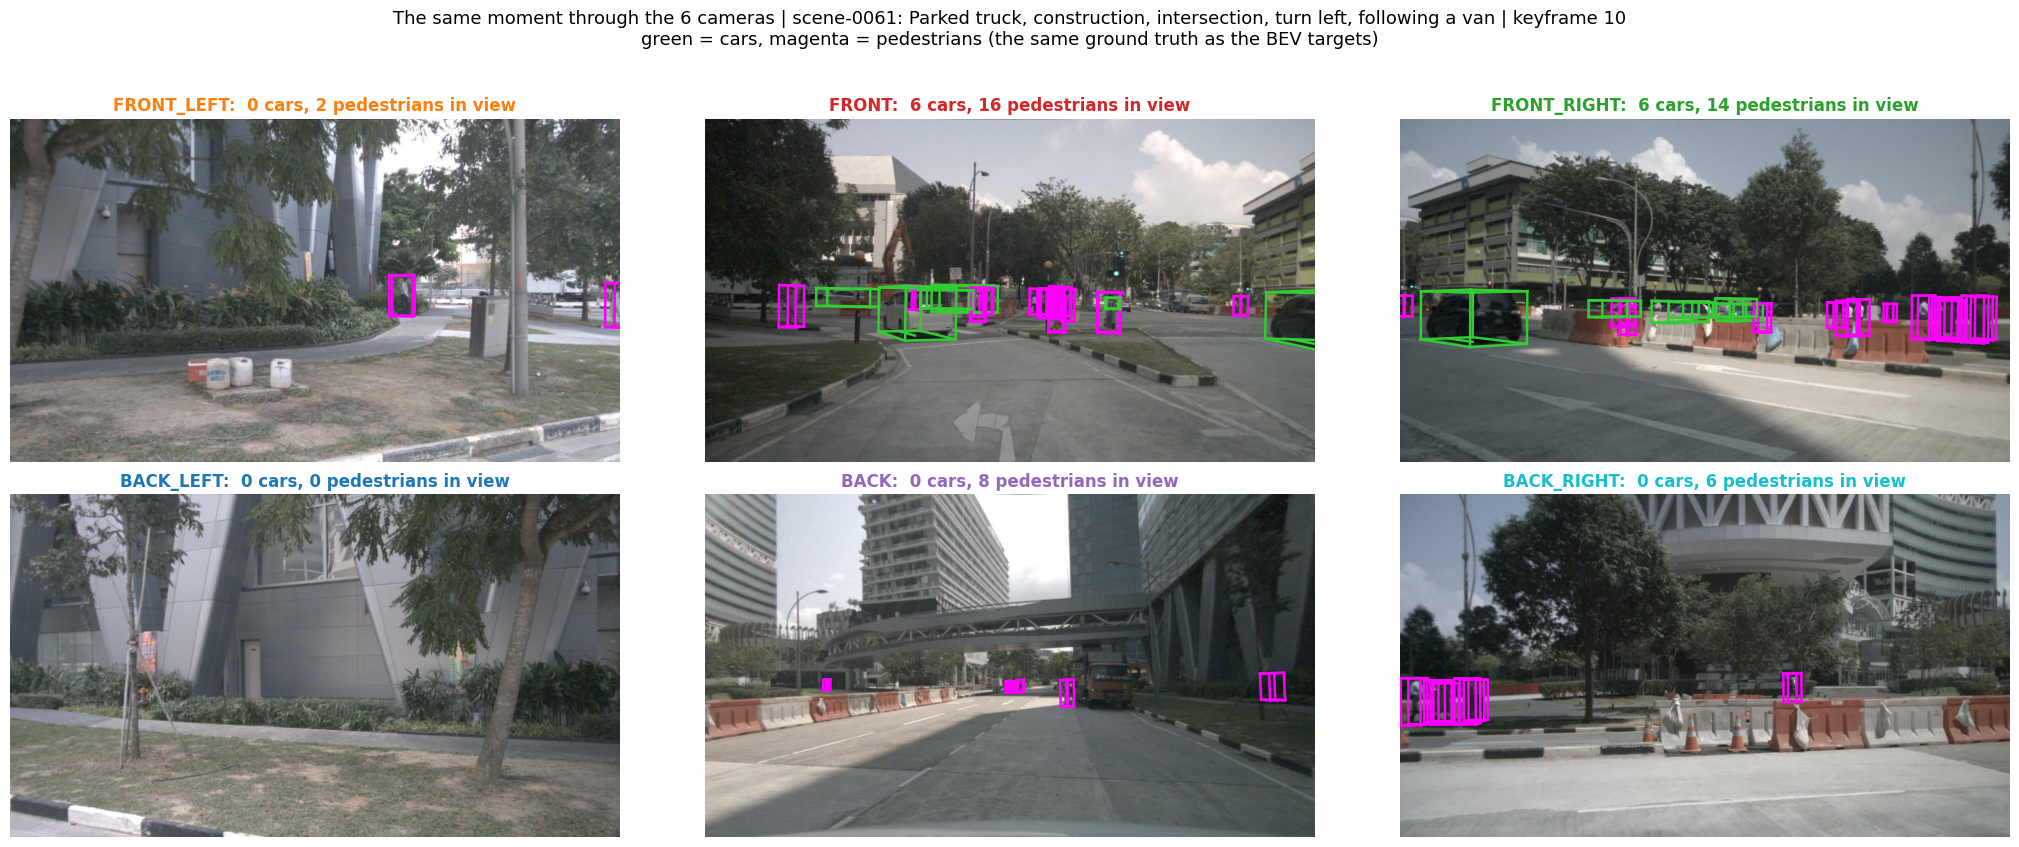

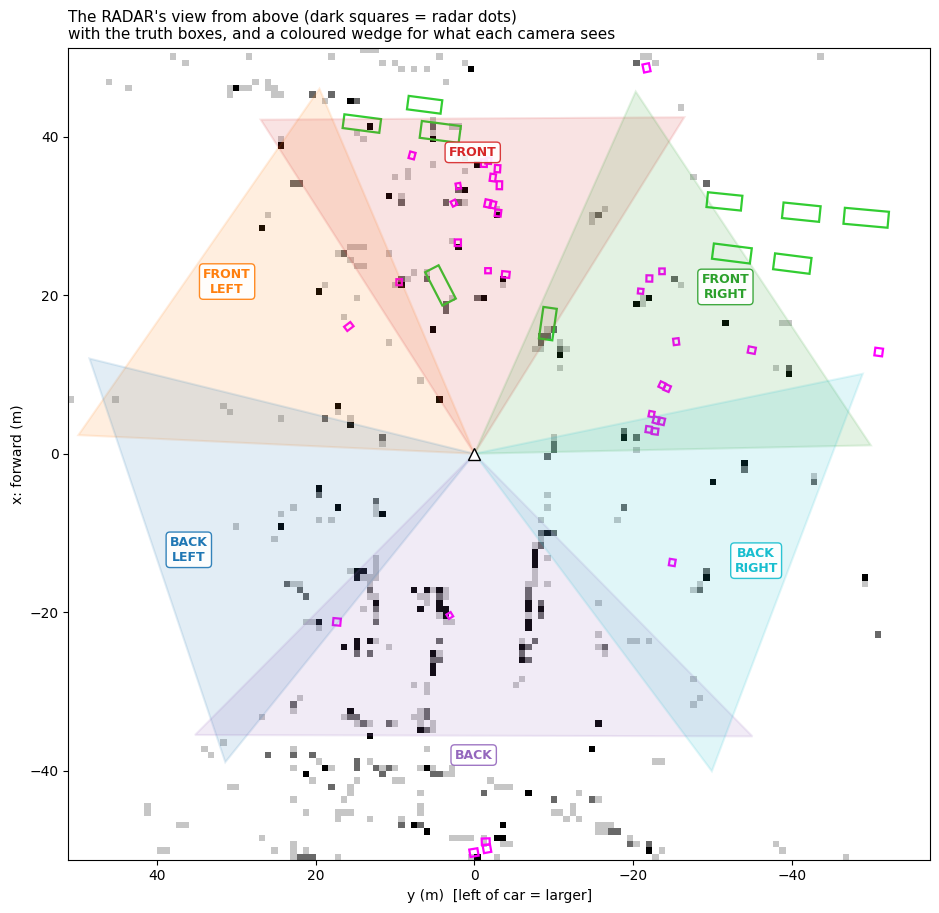

In [14]:
from matplotlib.patches import Polygon
from nuscenes.utils.geometry_utils import BoxVisibility
from PIL import Image

from bev_targets import category_to_class

CAMS = ["CAM_FRONT_LEFT", "CAM_FRONT", "CAM_FRONT_RIGHT", "CAM_BACK_LEFT", "CAM_BACK", "CAM_BACK_RIGHT"]
CAM_COLORS = dict(zip(CAMS, ["tab:orange", "tab:red", "tab:green", "tab:blue", "tab:purple", "tab:cyan"]))
ann_tokens = [a for a in sample["anns"] if category_to_class(nusc.get("sample_annotation", a)["category_name"]) is not None]

# ---------- Figure 1: the 6 cameras, with the ground-truth boxes drawn on the pictures ----------
fig, axes = plt.subplots(2, 3, figsize=(21, 8.6))
for ax, cam in zip(axes.flat, CAMS):
    path, cam_boxes, K = nusc.get_sample_data(sample["data"][cam], BoxVisibility.ANY, selected_anntokens=ann_tokens)
    ax.imshow(Image.open(path))
    n = [0, 0]
    for b in cam_boxes:
        cls = category_to_class(nusc.get("sample_annotation", b.token)["category_name"])
        b.render(ax, view=np.array(K), normalize=True, colors=(COLORS[cls],) * 3, linewidth=1.8)
        n[cls] += 1
    ax.set_xlim(0, 1600)
    ax.set_ylim(900, 0)
    ax.axis("off")
    ax.set_title(f"{cam.replace('CAM_', '')}:  {n[0]} cars, {n[1]} pedestrians in view", fontsize=12, fontweight="bold", color=CAM_COLORS[cam])
fig.suptitle(f"The same moment through the 6 cameras | {scene['name']}: {scene['description']} | keyframe 10\n"
             "green = cars, magenta = pedestrians (the same ground truth as the BEV targets)", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.94], h_pad=3)
plt.show()

# ---------- Figure 2: the radar map, with the field of view of every camera ----------
fig, ax = plt.subplots(figsize=(9.5, 9.5))
ax.imshow(np.minimum(item["bev"][0].numpy(), 3)[::-1, ::-1], extent=ext, cmap="Greys", vmin=0, vmax=3)
draw_boxes(ax)
base(ax)
for cam in CAMS:
    sd = nusc.get("sample_data", sample["data"][cam])
    cs = nusc.get("calibrated_sensor", sd["calibrated_sensor_token"])
    half = np.arctan(sd["width"] / 2 / np.array(cs["camera_intrinsic"])[0, 0])   # half of the horizontal field of view
    fwd = Quaternion(cs["rotation"]).rotate([0, 0, 1])                           # optical axis of the camera, in the ego frame
    theta = np.arctan2(fwd[1], fwd[0])                                           # angle from "forward" towards "left"
    edge = [(50 * np.sin(theta + s * half), 50 * np.cos(theta + s * half)) for s in (-1, 1)]   # (y, x) of the two far corners
    ax.add_patch(Polygon([(0, 0), *edge], closed=True, fc=CAM_COLORS[cam], alpha=0.13, ec=CAM_COLORS[cam], lw=1.5))
    ax.text(38 * np.sin(theta), 38 * np.cos(theta), cam.replace("CAM_", "").replace("_", "\n"), ha="center", va="center",
            fontsize=9, fontweight="bold", color=CAM_COLORS[cam], bbox=dict(boxstyle="round", fc="white", ec=CAM_COLORS[cam], alpha=0.9))
ax.set_title("The RADAR's view from above (dark squares = radar dots)\nwith the truth boxes, and a coloured wedge for what each camera sees",
             fontsize=11, loc="left")
plt.tight_layout()
plt.show()

## 5. The radar network (learned pillar encoder + BEV backbone)

In section 2 we built the pillar features by hand (mean speed, max RCS, ...). Now the network **learns** what to compute (`code/radar/model.py`):

1. **Pillar encoder (PointNet).** Every dot gets its 8 raw numbers plus how far it sits from the middle of its square and from the average dot of that square. A small MLP turns each dot into 64 numbers, then the **max over the dots of one square** gives that square one 64-number summary. Only squares that contain dots are computed (the map is about 97% empty), and empty squares stay 0.
2. **Small U-Net.** A CNN over the resulting 64 x 128 x 128 pseudo-image. It zooms out (128 > 64 > 32) so a square can see its neighbourhood, then zooms back in.
3. **Two heads.** One predicts the car / pedestrian heatmap, the other the box values, exactly the targets from section 4.

Loss: CenterNet focal loss on the heatmap plus L1 on the box values at object centres (`code/radar/train.py`).

parameters: pillar encoder 5,312 | U-Net 1,845,888 | heads 74,504 | total 1,925,704


points         (4, 1307, 8)   (batch, dots, 8 numbers per dot)
pseudo-image   (4, 64, 128, 128) (batch, 64 numbers per square, 128, 128)
heatmap logits (4, 2, 128, 128)  reg (4, 6, 128, 128)


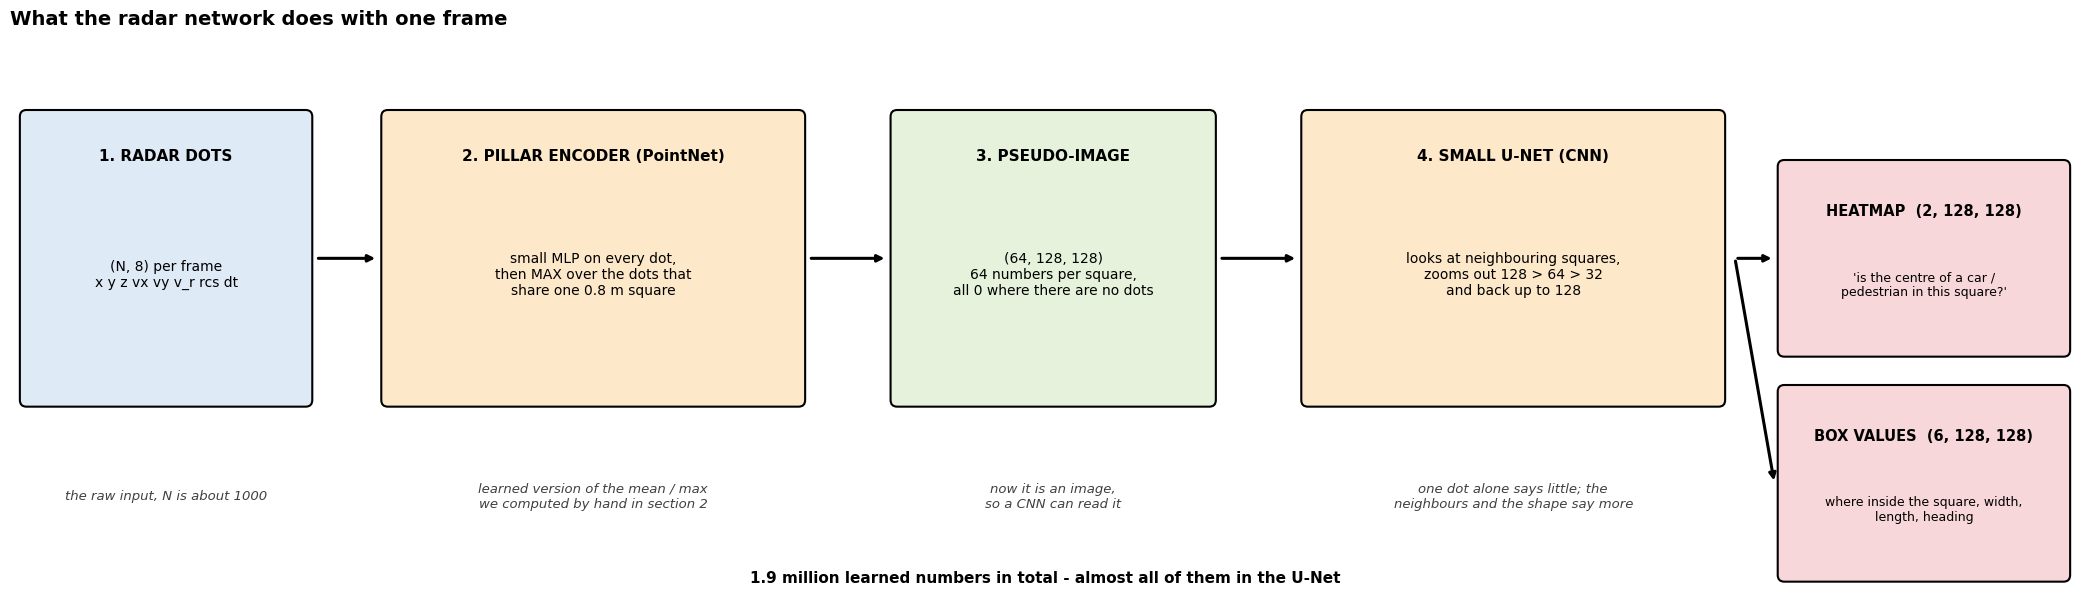

In [15]:
import torch
from matplotlib.patches import FancyBboxPatch

from model import RadarPillarNet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net = RadarPillarNet().to(device)
n = lambda m: sum(p.numel() for p in m.parameters())
print(f"parameters: pillar encoder {n(net.encoder):,} | U-Net {n(net.backbone):,} | heads {n(net.hm_head) + n(net.reg_head):,} | total {n(net):,}")

demo = collate([target_ds[i] for i in range(4)])
with torch.no_grad():
    pseudo = net.encoder(demo["points"].to(device), demo["mask"].to(device))
    out = net(demo["points"].to(device), demo["mask"].to(device))
print("points        ", tuple(demo["points"].shape), "  (batch, dots, 8 numbers per dot)")
print("pseudo-image  ", tuple(pseudo.shape), "(batch, 64 numbers per square, 128, 128)")
print("heatmap logits", tuple(out["hm"].shape), " reg", tuple(out["reg"].shape))

# ---------- architecture, in plain words ----------
fig, ax = plt.subplots(figsize=(21, 6.2))
ax.set_xlim(0, 126)
ax.set_ylim(0, 34)
ax.axis("off")
boxes_ = [
    (1, 17, "1. RADAR DOTS", "(N, 8) per frame\nx y z vx vy v_r rcs dt", "the raw input, N is about 1000", "#dfeaf7"),
    (23, 25, "2. PILLAR ENCODER (PointNet)", "small MLP on every dot,\nthen MAX over the dots that\nshare one 0.8 m square", "learned version of the mean / max\nwe computed by hand in section 2", "#fde9c9"),
    (54, 19, "3. PSEUDO-IMAGE", "(64, 128, 128)\n64 numbers per square,\nall 0 where there are no dots", "now it is an image,\nso a CNN can read it", "#e6f2dc"),
    (79, 25, "4. SMALL U-NET (CNN)", "looks at neighbouring squares,\nzooms out 128 > 64 > 32\nand back up to 128", "one dot alone says little; the\nneighbours and the shape say more", "#fde9c9"),
]
for x0, w, title, body, why, colour in boxes_:
    ax.add_patch(FancyBboxPatch((x0, 12), w, 17, boxstyle="round,pad=0.4", fc=colour, ec="k", lw=1.5))
    ax.text(x0 + w / 2, 26.6, title, ha="center", va="center", fontsize=11, fontweight="bold")
    ax.text(x0 + w / 2, 19.5, body, ha="center", va="center", fontsize=10)
    ax.text(x0 + w / 2, 6.2, why, ha="center", va="center", fontsize=9.5, style="italic", color="0.25")
for x0, x1 in ((18.6, 22.4), (48.6, 53.4), (73.6, 78.4)):
    ax.annotate("", xy=(x1, 20.5), xytext=(x0, 20.5), arrowprops=dict(arrowstyle="-|>", lw=2.2))
for y0, title, body, colour in ((20.5, "HEATMAP  (2, 128, 128)", "'is the centre of a car /\npedestrian in this square?'", "#f8d7da"), (7.0, "BOX VALUES  (6, 128, 128)", "where inside the square, width,\nlength, heading", "#f8d7da")):
    ax.add_patch(FancyBboxPatch((108, y0 - 5.5), 17, 11, boxstyle="round,pad=0.4", fc=colour, ec="k", lw=1.5))
    ax.text(116.5, y0 + 2.8, title, ha="center", va="center", fontsize=10.5, fontweight="bold")
    ax.text(116.5, y0 - 1.6, body, ha="center", va="center", fontsize=9)
    ax.annotate("", xy=(107.4, y0), xytext=(105, 20.5), arrowprops=dict(arrowstyle="-|>", lw=2.2))
ax.text(63, 1.0, f"{n(net) / 1e6:.1f} million learned numbers in total - almost all of them in the U-Net", ha="center", fontsize=11, fontweight="bold")
ax.set_title("What the radar network does with one frame", fontsize=14, fontweight="bold", loc="left")
plt.tight_layout()
plt.show()

## 6. Smoke test: train on mini

Goal from the roadmap: check that the pipeline works end to end and that **the loss goes down**. 25 epochs on the 315 training keyframes take about 80 seconds. Score = AP with a 2 m centre-distance rule (a detection counts if its centre is within 2 m of a true centre); 1.0 is perfect.

**Result.** The loss on the training frames falls steadily (smoke test passed) and the network scores about 0.97 AP for cars and 0.67 for pedestrians on frames it has seen, so encoder, targets, loss and decoding all work. On the val scenes it scores about 0.07 for cars and 0.01 for pedestrians: above an untrained network (0.02 and 0.00), but far from good, and the val loss rises after the first few epochs. With only 8 training scenes the network memorises them, which is the expected outcome for mini. The step that should fix it is the next one on the roadmap: more data (trainval), plus augmentation such as mirroring the scene.

In [16]:
import time

import train as T

val_full = RadarPillarDataset(nusc, "mini_val", with_targets=True)          # val keeps keyframe 0
train_items = [target_ds[i] for i in range(len(target_ds))]                 # held in memory: 315 keyframes, frame 0 of each scene dropped
val_items = [val_full[i] for i in range(len(val_full))]

torch.manual_seed(0)
net = RadarPillarNet().to(device)
t0 = time.time()
history = T.train(net, train_items, val_items, device, epochs=25, batch_size=8, lr=2e-3)
print(f"training took {time.time() - t0:.0f}s")

(ROOT / "checkpoints").mkdir(exist_ok=True)
torch.save(net.state_dict(), ROOT / "checkpoints" / "radar_pillar_mini_smoke.pt")
final_train = T.evaluate(net, train_items[:120], device)                    # frames the network was trained on
final_val = T.evaluate(net, val_items, device)                              # frames it has never seen
untrained_val = T.evaluate(RadarPillarNet().to(device), val_items, device)
for name, r in (("train frames", final_train), ("val frames", final_val), ("untrained net, val", untrained_val)):
    print(f"{name:20s} AP@2m  car {r['ap_car']:.3f}  pedestrian {r['ap_ped']:.3f}")

epoch  1/25 | train loss 3.411 (hm 2.823 reg 0.588) | val loss 3.052 | val AP@2m car 0.021 ped 0.046 | 3s


epoch  2/25 | train loss 2.671 (hm 2.215 reg 0.456) | val loss 3.138 | val AP@2m car 0.098 ped 0.020 | 3s


epoch  3/25 | train loss 2.498 (hm 2.086 reg 0.412) | val loss 2.912 | val AP@2m car 0.062 ped 0.051 | 3s


epoch  4/25 | train loss 2.360 (hm 1.982 reg 0.378) | val loss 3.046 | val AP@2m car 0.080 ped 0.029 | 3s


epoch  5/25 | train loss 2.202 (hm 1.848 reg 0.354) | val loss 2.957 | val AP@2m car 0.087 ped 0.035 | 3s


...

epoch 22/25 | train loss 0.282 (hm 0.097 reg 0.185) | val loss 5.033 | val AP@2m car 0.072 ped 0.018 | 3s


epoch 23/25 | train loss 0.275 (hm 0.092 reg 0.183) | val loss 5.062 | val AP@2m car 0.066 ped 0.016 | 3s


epoch 24/25 | train loss 0.268 (hm 0.086 reg 0.181) | val loss 5.078 | val AP@2m car 0.069 ped 0.017 | 3s


epoch 25/25 | train loss 0.268 (hm 0.088 reg 0.180) | val loss 5.084 | val AP@2m car 0.069 ped 0.016 | 3s
training took 75s


train frames         AP@2m  car 0.980  pedestrian 0.652
val frames           AP@2m  car 0.069  pedestrian 0.016
untrained net, val   AP@2m  car 0.016  pedestrian 0.000


### 6b. Loss and detection score, explained on the figure

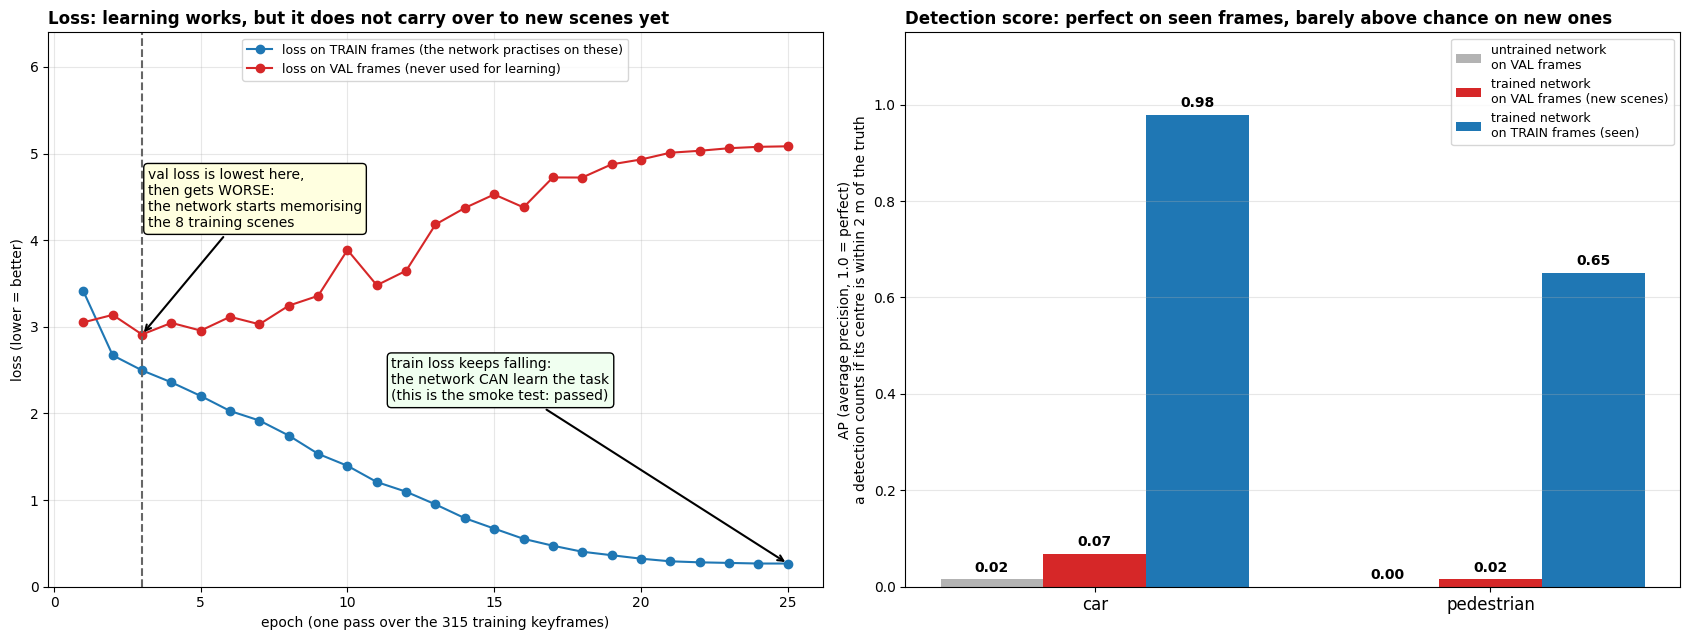

In [17]:
ep = [h["epoch"] for h in history]
tr_l = [h["train_loss"] for h in history]
va_l = [h["val_loss"] for h in history]
best = int(np.argmin(va_l))

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
ax = axes[0]
ax.plot(ep, tr_l, "o-", color="tab:blue", label="loss on TRAIN frames (the network practises on these)")
ax.plot(ep, va_l, "o-", color="tab:red", label="loss on VAL frames (never used for learning)")
ax.axvline(ep[best], color="0.4", ls="--")
ax.annotate("val loss is lowest here,\nthen gets WORSE:\nthe network starts memorising\nthe 8 training scenes",
            xy=(ep[best], va_l[best]), xytext=(3.2, 4.15), fontsize=10,
            bbox=dict(boxstyle="round", fc="lightyellow", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.annotate("train loss keeps falling:\nthe network CAN learn the task\n(this is the smoke test: passed)",
            xy=(ep[-1], tr_l[-1]), xytext=(11.5, 2.15), fontsize=10,
            bbox=dict(boxstyle="round", fc="honeydew", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_xlabel("epoch (one pass over the 315 training keyframes)")
ax.set_ylabel("loss (lower = better)")
ax.set_title("Loss: learning works, but it does not carry over to new scenes yet", fontsize=12, fontweight="bold", loc="left")
ax.set_ylim(0, 6.4)
ax.legend(loc="upper center", fontsize=9)
ax.grid(alpha=0.3)

ax = axes[1]
width = 0.26
labels = ["car", "pedestrian"]
vals = [("untrained network\non VAL frames", [untrained_val["ap_car"], untrained_val["ap_ped"]], "0.7"),
        ("trained network\non VAL frames (new scenes)", [final_val["ap_car"], final_val["ap_ped"]], "tab:red"),
        ("trained network\non TRAIN frames (seen)", [final_train["ap_car"], final_train["ap_ped"]], "tab:blue")]
for k, (name, v, colour) in enumerate(vals):
    bars = ax.bar(np.arange(2) + (k - 1) * width, v, width, label=name, color=colour)
    for b_, x_ in zip(bars, v):
        ax.text(b_.get_x() + b_.get_width() / 2, x_ + 0.015, f"{x_:.2f}", ha="center", fontsize=10, fontweight="bold")
ax.set_xticks(range(2))
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylim(0, 1.15)
ax.set_ylabel("AP (average precision, 1.0 = perfect)\na detection counts if its centre is within 2 m of the truth")
ax.set_title("Detection score: perfect on seen frames, barely above chance on new ones", fontsize=12, fontweight="bold", loc="left")
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

### 6c. What the network predicts

Top row: a frame from the training set. Bottom row: a frame from the val scenes that the network has never seen. Bright spots that sit inside the cyan circles mean the network found the object.

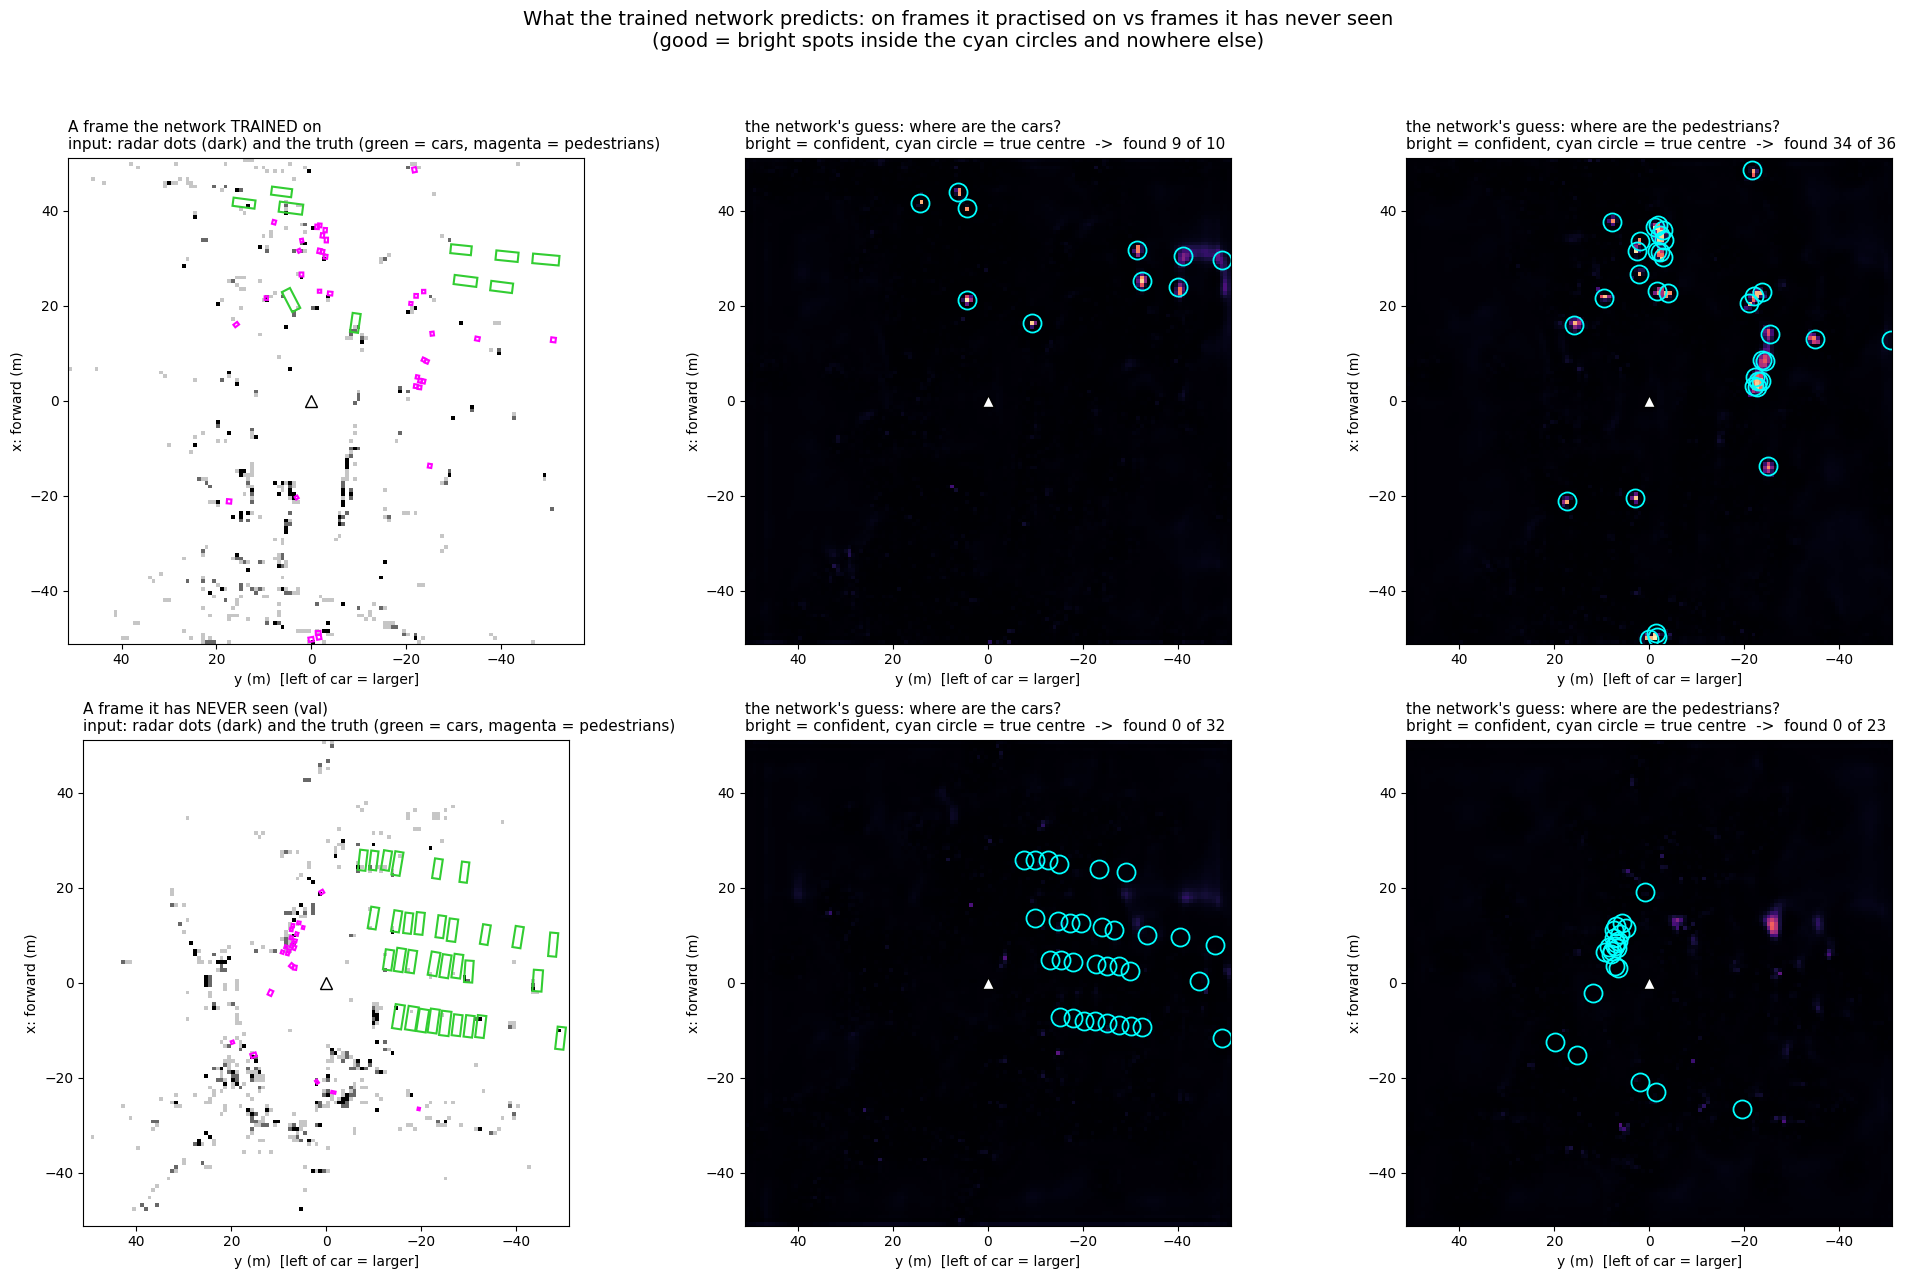

In [18]:
from matplotlib.patches import Polygon


@torch.no_grad()
def predict(item):
    net.eval()
    b = T.to_device(collate([item]), device)
    out = net(b["points"], b["mask"])
    return out["hm"].sigmoid()[0].cpu().numpy(), T.decode(out)[0]


def found(dets, truth, cls, thr=2.0, min_score=0.3):
    """How many true centres of this class have a confident detection within thr metres."""
    t = truth[truth[:, 0] == cls][:, 1:3]
    d = dets[(dets[:, 0] == cls) & (dets[:, 1] >= min_score)][:, 2:4]
    hit = sum(bool(len(d)) and np.hypot(d[:, 0] - x, d[:, 1] - y).min() < thr for x, y in t)
    return hit, len(t)


def draw(ax, bxs):
    for cls, x, y, w, l, yaw in bxs:
        c, s = np.cos(yaw), np.sin(yaw)
        corners = np.array([[l / 2, w / 2], [l / 2, -w / 2], [-l / 2, -w / 2], [-l / 2, w / 2]])
        xy = corners @ np.array([[c, s], [-s, c]]) + [x, y]
        ax.add_patch(Polygon(np.stack([xy[:, 1], xy[:, 0]], 1), closed=True, fill=False, ec=COLORS[int(cls)], lw=1.5))


train_item = train_items[target_ds.tokens.index(sample["token"])]                        # scene-0061, keyframe 10
count = lambda it, k: int((it["boxes"][:, 0] == k).sum())
val_item = max(val_items, key=lambda it: (min(count(it, 0), count(it, 1)), count(it, 0)))   # a val frame with both cars and pedestrians
rows = [("A frame the network TRAINED on", train_item), ("A frame it has NEVER seen (val)", val_item)]

fig, axes = plt.subplots(2, 3, figsize=(20, 13))
for r, (row_title, it) in enumerate(rows):
    hm, dets = predict(it)
    truth = it["boxes"].numpy()
    a = axes[r, 0]
    a.imshow(np.minimum(it["bev"][0].numpy(), 3)[::-1, ::-1], extent=ext, cmap="Greys", vmin=0, vmax=3)
    draw(a, truth)
    a.set_title(f"{row_title}\ninput: radar dots (dark) and the truth (green = cars, magenta = pedestrians)", fontsize=11, loc="left")
    for k, (name, colour) in enumerate((("car", "limegreen"), ("pedestrian", "magenta"))):
        a = axes[r, k + 1]
        a.imshow(hm[k][::-1, ::-1], extent=ext, cmap="magma", vmin=0, vmax=1)
        for cls, x, y, *_ in truth:
            if int(cls) == k:
                a.plot(y, x, "o", mfc="none", mec="cyan", ms=13, mew=1.3)
        hit, tot = found(dets, truth, k)
        a.set_title(f"the network's guess: where are the {name}s?\nbright = confident, cyan circle = true centre  ->  found {hit} of {tot}", fontsize=11, loc="left")
    for a in axes[r]:
        a.plot(0, 0, "w^", ms=9, mec="k")
        a.set_xlabel("y (m)  [left of car = larger]")
        a.set_ylabel("x: forward (m)")
fig.suptitle("What the trained network predicts: on frames it practised on vs frames it has never seen\n"
             "(good = bright spots inside the cyan circles and nowhere else)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 7. Mirror augmentation

**The problem from section 6:** with only 8 training scenes the network memorises them. **Augmentation** means showing the network slightly changed copies of the training data so it cannot memorise so easily. The simplest change for driving data is a **mirror**: flip the whole frame left <-> right (y becomes -y) with probability 1/2 while training. A car on the left becomes a car on the right, so the network sees twice as many different situations.

The flip has to be done consistently: the radar dots and every target change together (`mirror_batch` in `code/radar/train.py`). The figure below shows one frame before and after, and what exactly changes.

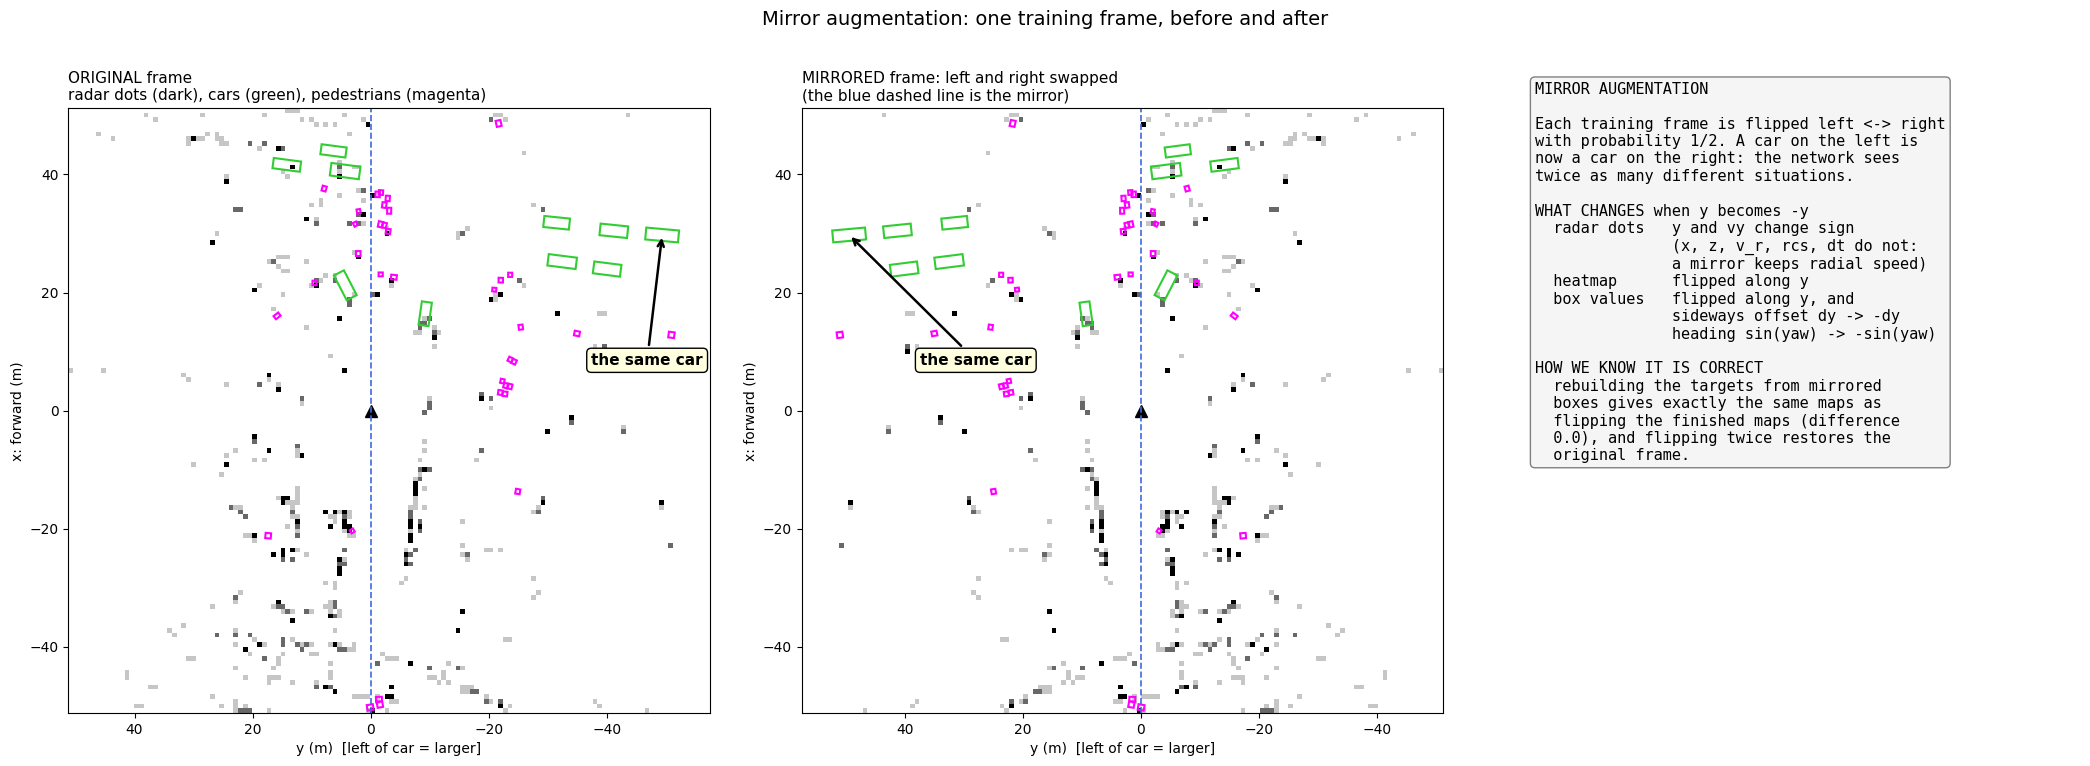

In [19]:
item0 = train_item                                            # scene-0061, keyframe 10 (same frame as before)
b0 = collate([item0])
b1 = T.mirror_batch(collate([item0]), torch.tensor([True]))    # the same frame, mirrored left <-> right
truth0 = item0["boxes"].numpy()
truth1 = truth0.copy()
truth1[:, 2] *= -1                                             # y  -> -y
truth1[:, 5] *= -1                                             # heading -> -heading


def show(ax, batch, truth, title):
    pts = batch["points"][0][batch["mask"][0]].numpy()
    ax.imshow(np.minimum(pillarize(pts)[0], 3)[::-1, ::-1], extent=ext, cmap="Greys", vmin=0, vmax=3)
    draw(ax, truth)
    ax.plot(0, 0, "k^", ms=9)
    ax.axvline(0, color="royalblue", ls="--", lw=1.2)
    ax.set_xlabel("y (m)  [left of car = larger]")
    ax.set_ylabel("x: forward (m)")
    ax.set_title(title, fontsize=11, loc="left")


fig, axes = plt.subplots(1, 3, figsize=(21, 7.6), gridspec_kw=dict(width_ratios=[1, 1, 0.85]))
show(axes[0], b0, truth0, "ORIGINAL frame\nradar dots (dark), cars (green), pedestrians (magenta)")
show(axes[1], b1, truth1, "MIRRORED frame: left and right swapped\n(the blue dashed line is the mirror)")
marker = truth0[np.argmax(np.where(truth0[:, 0] == 0, np.abs(truth0[:, 2]), -1))]      # the car furthest to one side
for a, y_ in ((axes[0], marker[2]), (axes[1], -marker[2])):
    a.annotate("the same car", xy=(y_, marker[1]), xytext=(y_ + (12 if y_ < 0 else -12), marker[1] - 22), fontsize=11, fontweight="bold",
               bbox=dict(boxstyle="round", fc="lightyellow", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.8))
axes[2].axis("off")
axes[2].text(0.0, 1.0,
             "MIRROR AUGMENTATION\n\n"
             "Each training frame is flipped left <-> right\nwith probability 1/2. A car on the left is\n"
             "now a car on the right: the network sees\ntwice as many different situations.\n\n"
             "WHAT CHANGES when y becomes -y\n"
             "  radar dots   y and vy change sign\n"
             "               (x, z, v_r, rcs, dt do not:\n"
             "               a mirror keeps radial speed)\n"
             "  heatmap      flipped along y\n"
             "  box values   flipped along y, and\n"
             "               sideways offset dy -> -dy\n"
             "               heading sin(yaw) -> -sin(yaw)\n\n"
             "HOW WE KNOW IT IS CORRECT\n"
             "  rebuilding the targets from mirrored\n"
             "  boxes gives exactly the same maps as\n"
             "  flipping the finished maps (difference\n"
             "  0.0), and flipping twice restores the\n"
             "  original frame.",
             va="top", ha="left", fontsize=11, family="monospace", bbox=dict(boxstyle="round", fc="whitesmoke", ec="0.5"))
fig.suptitle("Mirror augmentation: one training frame, before and after", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### 7b. The experiment

Same network, same 25 epochs, same settings; the only difference is `mirror=True` or `False`. Each is run with 3 random seeds, because val is only 2 scenes and one run would be too noisy to trust. (This cell trains 6 networks, about 8 minutes.)

In [20]:
import time

# Same network, same 25 epochs, same 3 random seeds; the only difference is mirror=True/False.
# 3 seeds because val is only 2 scenes: a single run would be too noisy to trust.
mirror_results = {}
t0 = time.time()
for name, use_mirror in (("baseline", False), ("mirror", True)):
    runs = []
    for seed in (0, 1, 2):
        torch.manual_seed(seed)
        m_net = RadarPillarNet().to(device)
        hist = T.train(m_net, train_items, val_items, device, epochs=25, batch_size=8, lr=2e-3, seed=seed,
                       mirror=use_mirror, log=lambda s: None)
        seen = T.evaluate(m_net, train_items[:120], device)
        runs.append(dict(history=hist, train_ap_car=seen["ap_car"], train_ap_ped=seen["ap_ped"]))
        h = hist[-1]
        print(f"{name:8s} seed {seed}: val AP car {h['val_ap_car']:.3f} ped {h['val_ap_ped']:.3f} | val loss {h['val_loss']:.2f} "
              f"| AP on train frames car {seen['ap_car']:.3f} ped {seen['ap_ped']:.3f}")
    mirror_results[name] = runs
print(f"took {time.time() - t0:.0f}s")

def mean_std(name, get):
    v = np.array([get(r) for r in mirror_results[name]])
    return v.mean(), v.std()

for name in mirror_results:
    print(f"\n{name}:")
    for label, get in (("val AP car", lambda r: r["history"][-1]["val_ap_car"]), ("val AP pedestrian", lambda r: r["history"][-1]["val_ap_ped"]),
                       ("val loss", lambda r: r["history"][-1]["val_loss"]), ("train-frames AP car", lambda r: r["train_ap_car"])):
        m, s = mean_std(name, get)
        print(f"  {label:20s} {m:.3f} +- {s:.3f}")

baseline seed 0: val AP car 0.071 ped 0.010 | val loss 5.12 | AP on train frames car 0.976 ped 0.659


baseline seed 1: val AP car 0.063 ped 0.016 | val loss 4.79 | AP on train frames car 0.967 ped 0.667


baseline seed 2: val AP car 0.075 ped 0.013 | val loss 5.03 | AP on train frames car 0.974 ped 0.671


mirror   seed 0: val AP car 0.115 ped 0.020 | val loss 3.46 | AP on train frames car 0.828 ped 0.500


mirror   seed 1: val AP car 0.122 ped 0.026 | val loss 3.26 | AP on train frames car 0.752 ped 0.449


mirror   seed 2: val AP car 0.112 ped 0.025 | val loss 3.41 | AP on train frames car 0.801 ped 0.485
took 492s

baseline:
  val AP car           0.070 +- 0.005
  val AP pedestrian    0.013 +- 0.002
  val loss             4.978 +- 0.141
  train-frames AP car  0.973 +- 0.004

mirror:
  val AP car           0.117 +- 0.004
  val AP pedestrian    0.024 +- 0.002
  val loss             3.378 +- 0.088
  train-frames AP car  0.794 +- 0.032


### 7c. Result, explained on the figure

**Result (mean of 3 runs, final epoch):** car AP on new scenes goes from about 0.07 to 0.12 and pedestrian AP from about 0.01 to 0.03. The loss on new scenes stays around 3.4 instead of climbing to 5, and the network memorises less (AP on its training frames: 0.97 -> 0.80 for cars).

**Honest reading:** the *lowest* loss on new scenes reached at any epoch is about the same with and without mirroring (about 2.7 to 2.8). If we had stopped at the best epoch, the car AP would be about 0.12 without and 0.15 with mirroring (note on panel 2). So a good part of the final-epoch gain is "mirroring stops the network from overfitting", and a smaller part is real extra learning. Scores are still very low. The real fix is more scenes (trainval); mirroring is a cheap extra to keep for that run.

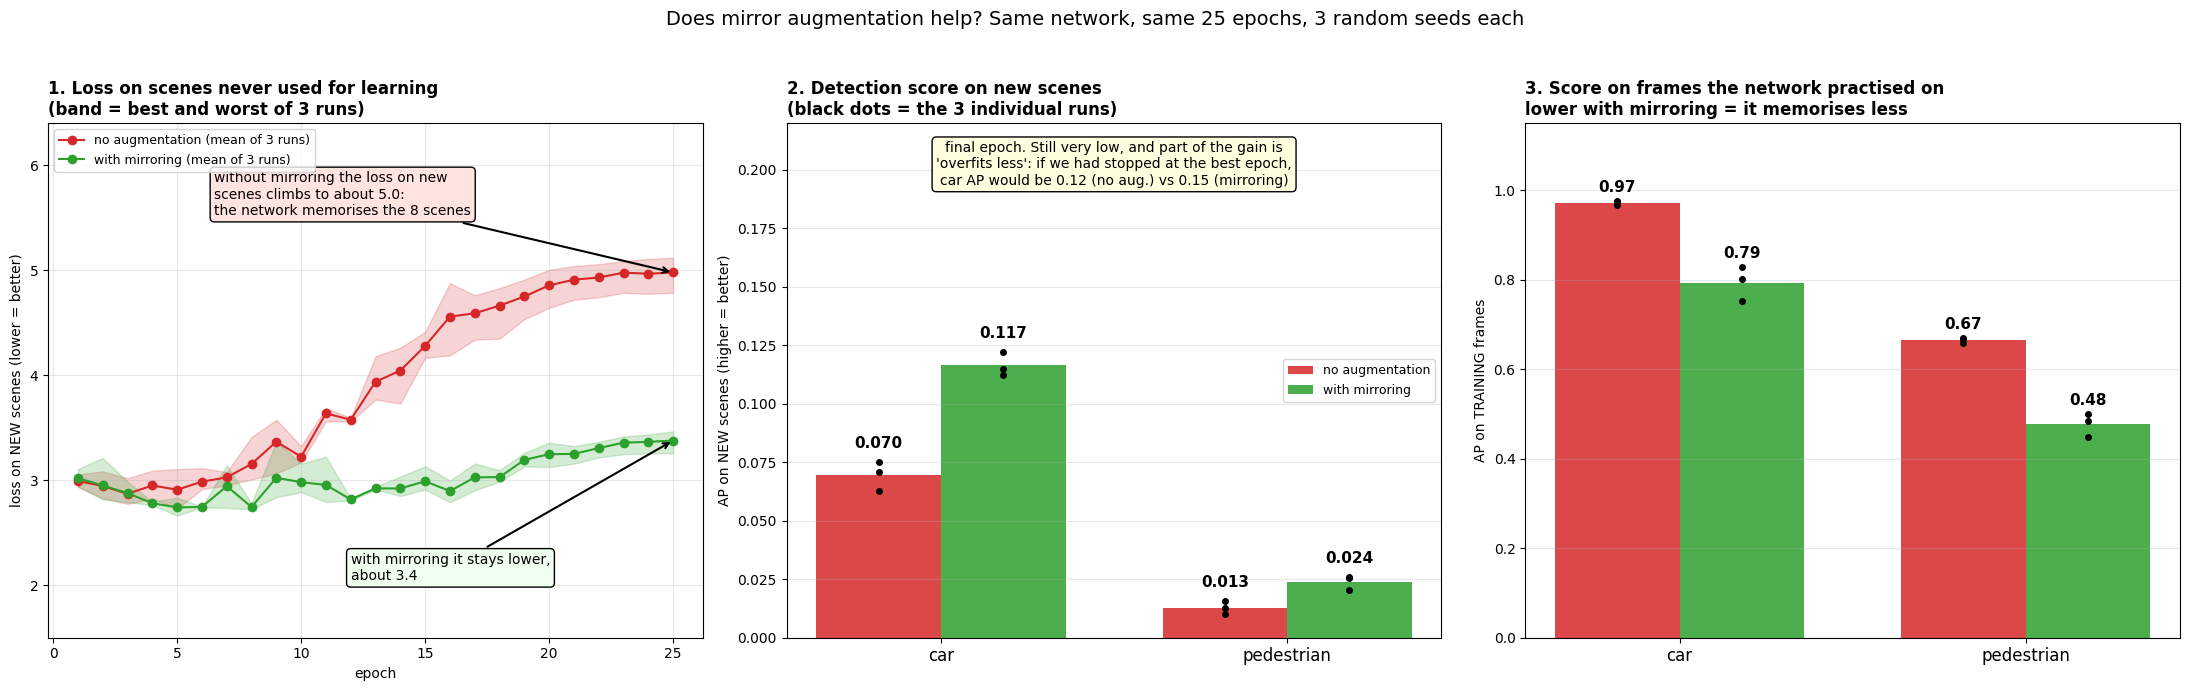

In [21]:
COL = {"baseline": "tab:red", "mirror": "tab:green"}
NAME = {"baseline": "no augmentation", "mirror": "with mirroring"}
final = lambda name, key: np.array([r["history"][-1][key] for r in mirror_results[name]])
curve = lambda name, key: np.array([[h[key] for h in r["history"]] for r in mirror_results[name]])

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# 1) validation loss over the epochs
ax = axes[0]
epochs_ = np.arange(1, curve("baseline", "val_loss").shape[1] + 1)
for name in mirror_results:
    c = curve(name, "val_loss")
    ax.plot(epochs_, c.mean(0), "o-", color=COL[name], label=f"{NAME[name]} (mean of 3 runs)")
    ax.fill_between(epochs_, c.min(0), c.max(0), color=COL[name], alpha=0.2)
ax.annotate(f"without mirroring the loss on new\nscenes climbs to about {final('baseline', 'val_loss').mean():.1f}:\nthe network memorises the 8 scenes",
            xy=(25, final("baseline", "val_loss").mean()), xytext=(6.5, final("baseline", "val_loss").mean() + 0.55), fontsize=10,
            bbox=dict(boxstyle="round", fc="mistyrose", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.annotate(f"with mirroring it stays lower,\nabout {final('mirror', 'val_loss').mean():.1f}",
            xy=(25, final("mirror", "val_loss").mean()), xytext=(12, 2.05), fontsize=10,
            bbox=dict(boxstyle="round", fc="honeydew", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_ylim(1.5, 6.4)
ax.set_xlabel("epoch")
ax.set_ylabel("loss on NEW scenes (lower = better)")
ax.set_title("1. Loss on scenes never used for learning\n(band = best and worst of 3 runs)", fontsize=12, fontweight="bold", loc="left")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)

# 2) detection score on new scenes
ax = axes[1]
width = 0.36
for k, name in enumerate(mirror_results):
    for j, key in enumerate(("val_ap_car", "val_ap_ped")):
        v = final(name, key)
        x = j + (k - 0.5) * width
        ax.bar(x, v.mean(), width, color=COL[name], alpha=0.85, label=NAME[name] if j == 0 else None)
        ax.plot([x] * len(v), v, "k.", ms=8)
        ax.text(x, v.max() + 0.006, f"{v.mean():.3f}", ha="center", fontsize=11, fontweight="bold")
ax.set_xticks([0, 1])
ax.set_xticklabels(["car", "pedestrian"], fontsize=12)
ax.set_ylim(0, 0.22)
ax.set_ylabel("AP on NEW scenes (higher = better)")
ax.set_title("2. Detection score on new scenes\n(black dots = the 3 individual runs)", fontsize=12, fontweight="bold", loc="left")
best_ap = {n: np.mean([max(h["val_ap_car"] for h in r["history"]) for r in mirror_results[n]]) for n in mirror_results}
ax.text(0.5, 0.965, "final epoch. Still very low, and part of the gain is\n'overfits less': if we had stopped at the best epoch,\n"
        f"car AP would be {best_ap['baseline']:.2f} (no aug.) vs {best_ap['mirror']:.2f} (mirroring)",
        transform=ax.transAxes, ha="center", va="top", fontsize=10, bbox=dict(boxstyle="round", fc="lightyellow", ec="k"))
ax.legend(loc="center right", fontsize=9)
ax.grid(alpha=0.3, axis="y")

# 3) how much of the training set is memorised
ax = axes[2]
for k, name in enumerate(mirror_results):
    for j, key in enumerate(("train_ap_car", "train_ap_ped")):
        v = np.array([r[key] for r in mirror_results[name]])
        x = j + (k - 0.5) * width
        ax.bar(x, v.mean(), width, color=COL[name], alpha=0.85)
        ax.plot([x] * len(v), v, "k.", ms=8)
        ax.text(x, v.max() + 0.02, f"{v.mean():.2f}", ha="center", fontsize=11, fontweight="bold")
ax.set_xticks([0, 1])
ax.set_xticklabels(["car", "pedestrian"], fontsize=12)
ax.set_ylim(0, 1.15)
ax.set_ylabel("AP on TRAINING frames")
ax.set_title("3. Score on frames the network practised on\nlower with mirroring = it memorises less", fontsize=12, fontweight="bold", loc="left")
ax.grid(alpha=0.3, axis="y")

fig.suptitle("Does mirror augmentation help? Same network, same 25 epochs, 3 random seeds each", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Next (M1)

- [x] Torch `Dataset` over all keyframes, raw points cached to `cache/radar_points/` (section 3)
- [x] Ground-truth BEV targets for the detection proxy, cars / pedestrians as CenterNet-style heatmap + box regression (section 4, `code/radar/bev_targets.py`)
- [x] Learned pillar encoder (PointNet over per-pillar points) + small BEV backbone (section 5, `code/radar/model.py`)
- [x] Train on mini as a smoke test: the loss goes down, but the network memorises the 8 scenes (section 6)
- [x] Mirror augmentation (section 7): keeps the loss on new scenes from climbing, car AP on new scenes 0.07 -> 0.12, still low
- [ ] Scale to trainval (more scenes is the real fix), keep mirroring, maybe add small rotation / dropping random dots